# Exploratory Data Analysis - Predict Future Sales

## 2. Comprensión inicial del dataset

### 2.a Carga de los archivos y primeras filas

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

RAW = Path("..") / "data" / "raw"

sales = pd.read_csv(RAW / "sales_train.csv")
items = pd.read_csv(RAW / "items.csv")
item_categories = pd.read_csv(RAW / "item_categories.csv")
shops = pd.read_csv(RAW / "shops.csv")
test = pd.read_csv(RAW / "test.csv")

# Copia de la fecha original en texto, para validar el formato en 3.b.
fecha_texto = sales["date"].copy()

tablas = {
    "sales_train": sales,
    "items": items,
    "item_categories": item_categories,
    "shops": shops,
    "test": test,
}

In [2]:
sales.head()

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,02.01.2013,0,59,22154,999.00,1.0
1,03.01.2013,0,25,2552,899.00,1.0
2,05.01.2013,0,25,2552,899.00,-1.0
3,06.01.2013,0,25,2554,1709.05,1.0
4,15.01.2013,0,25,2555,1099.00,1.0


**Interpretación:** cada fila es una transacción de un producto en una tienda y un día. La fecha viene como texto `dd.mm.aaaa`. Ya en las primeras filas aparece una devolución: el producto 2552 de la tienda 25 se vende el 03.01.2013 y tiene `item_cnt_day = -1` el 05.01.2013.

In [3]:
items.head()

,item_name,item_id,item_category_id
0,! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,0,40
1,!ABBYY FineReader 12 Professional Edition Full...,1,76
2,***В ЛУЧАХ СЛАВЫ (UNV) D,2,40
3,***ГОЛУБАЯ ВОЛНА (Univ) D,3,40
4,***КОРОБКА (СТЕКЛО) D,4,40


**Interpretación:** es el catálogo que une cada `item_id` con su categoría. Los nombres están en ruso y traen ruido de texto (símbolos como `!` y `***`, y espacios de relleno), por lo que `item_category_id` es más útil que `item_name` para agrupar productos.

In [4]:
item_categories.head()

,item_category_name,item_category_id
0,PC - Гарнитуры/Наушники,0
1,Аксессуары - PS2,1
2,Аксессуары - PS3,2
3,Аксессуары - PS4,3
4,Аксессуары - PSP,4


**Interpretación:** los nombres siguen el patrón `familia - subcategoría` (por ejemplo, `Аксессуары - PS2`, accesorios de PS2), lo que permitiría separar una categoría más general en etapas posteriores.

In [5]:
shops.head()

,shop_name,shop_id
0,"!Якутск Орджоникидзе, 56 фран",0
1,"!Якутск ТЦ ""Центральный"" фран",1
2,"Адыгея ТЦ ""Мега""",2
3,"Балашиха ТРК ""Октябрь-Киномир""",3
4,"Волжский ТЦ ""Волга Молл""",4


**Interpretación:** el nombre de cada tienda empieza con la ciudad (Якутск, Адыгея, Балашиха, Волжский), seguida de datos del centro comercial. Las tiendas 0 y 1 están en Якутск y llevan `!` al inicio, un detalle a revisar cuando se busquen tiendas repetidas en la sección 4.

In [6]:
test.head()

,ID,shop_id,item_id
0,0,5,5037
1,1,5,5320
2,2,5,5233
3,3,5,5232
4,4,5,5268


**Interpretación:** `test` solo contiene los pares tienda-producto a predecir con su `ID`. No trae fecha, precio ni cantidad, así que toda la información para el modelo debe salir del histórico.

### 2.b Tamaño de cada tabla

In [7]:
pd.DataFrame(
    [{"tabla": nombre, "filas": df.shape[0], "columnas": df.shape[1]} for nombre, df in tablas.items()]
).set_index("tabla")

,filas,columnas
tabla,,
sales_train,2935849,6
items,22170,3
item_categories,84,2
shops,60,2
test,214200,3


**Interpretación:** el histórico tiene 2,935,849 transacciones, frente a catálogos pequeños de 22,170 productos, 84 categorías y 60 tiendas. `test` tiene 214,200 filas, que equivalen exactamente a 42 tiendas × 5,100 productos (ver 3.a): se pide predecir la combinación completa de esas tiendas y productos, aunque un par no se haya vendido nunca.

### 2.c Descripción de las columnas y variable objetivo

Descripción de las columnas de las tablas del dataset:

| Columna | Tabla(s) | Tipo | Descripción |
|---|---|---|---|
| `date` | `sales_train` | Fecha (texto `dd.mm.aaaa` en el archivo) | Día en que ocurrió la transacción. |
| `date_block_num` | `sales_train` | Entero ordinal | Número de mes consecutivo: 0 = enero 2013, 33 = octubre 2015. |
| `shop_id` | `sales_train`, `shops`, `test` | Identificador categórico | Identificador único de la tienda (sucursal). |
| `item_id` | `sales_train`, `items`, `test` | Identificador categórico | Identificador único del producto. |
| `item_price` | `sales_train` | Numérica continua | Precio unitario del producto en esa transacción. |
| `item_cnt_day` | `sales_train` | Numérica discreta | Unidades vendidas en el día; los valores negativos representan devoluciones. |
| `item_name` | `items` | Texto | Nombre del producto. |
| `item_category_id` | `items`, `item_categories` | Identificador categórico | Identificador de la categoría del producto. |
| `item_category_name` | `item_categories` | Texto | Nombre de la categoría del producto. |
| `shop_name` | `shops` | Texto | Nombre de la tienda. |
| `ID` | `test` | Identificador | Identificador de cada par tienda-producto a predecir. |

**Variable objetivo:** la suma mensual de `item_cnt_day` por tienda-producto, es decir, las unidades vendidas de cada par (`shop_id`, `item_id`) en cada mes (`date_block_num`). No existe como columna en los archivos: se construye agregando `sales_train`, y debe predecirse para noviembre de 2015 en los pares de `test.csv`.

### 2.d Rango temporal de los datos

In [8]:
fechas = pd.to_datetime(fecha_texto, format="%d.%m.%Y")

pd.Series(
    {
        "fecha mínima": fechas.min().date(),
        "fecha máxima": fechas.max().date(),
        "días en el rango": (fechas.max() - fechas.min()).days + 1,
        "meses calendario distintos": fechas.dt.to_period("M").nunique(),
        "date_block_num mínimo": sales["date_block_num"].min(),
        "date_block_num máximo": sales["date_block_num"].max(),
        "date_block_num distintos": sales["date_block_num"].nunique(),
    },
    name="valor",
).to_frame()

,valor
fecha mínima,2013-01-01
fecha máxima,2015-10-31
días en el rango,1034
meses calendario distintos,34
date_block_num mínimo,0
date_block_num máximo,33
date_block_num distintos,34


**Interpretación:** los datos van del 1 de enero de 2013 al 31 de octubre de 2015, es decir, 1,034 días y 34 meses calendario. `date_block_num` toma exactamente 34 valores (0 a 33), como indica el PDF, y el mes a predecir (noviembre de 2015) es el inmediatamente siguiente al último mes observado.

## 3. Validación de la estructura de los datos

### 3.a Tipos de datos de cada variable

In [9]:
tipo_semantico = {
    "date": "fecha (guardada como texto)",
    "date_block_num": "numérica ordinal (mes)",
    "shop_id": "categórica (identificador)",
    "item_id": "categórica (identificador)",
    "item_price": "numérica continua",
    "item_cnt_day": "numérica discreta",
    "item_name": "categórica (texto)",
    "item_category_id": "categórica (identificador)",
    "item_category_name": "categórica (texto)",
    "shop_name": "categórica (texto)",
    "ID": "categórica (identificador)",
}

pd.DataFrame(
    [
        {
            "tabla": nombre,
            "columna": columna,
            "dtype en pandas": str(df[columna].dtype),
            "tipo semántico": tipo_semantico[columna],
            "valores distintos": df[columna].nunique(),
        }
        for nombre, df in tablas.items()
        for columna in df.columns
    ]
).set_index(["tabla", "columna"])

dtype en pandas               tipo semántico  valores distintos
tabla           columna                                                                           
sales_train     date                           str  fecha (guardada como texto)               1034
                date_block_num               int64       numérica ordinal (mes)                 34
                shop_id                      int64   categórica (identificador)                 60
                item_id                      int64   categórica (identificador)              21807
                item_price                 float64            numérica continua              19993
                item_cnt_day               float64            numérica discreta                198
items           item_name                      str           categórica (texto)              22170
                item_id                      int64   categórica (identificador)              22170
                item_category_id             int64   categórica (identificador)                 84
item_categories item_category_name             str           categórica (texto)                 84
                item_category_id             int64   categórica (identificador)                 84
shops           shop_name                      str           categórica (texto)                 60
                shop_id                      int64   categórica (identificador)                 60
test            ID                           int64   categórica (identificador)             214200
                shop_id                      int64   categórica (identificador)                 42
                item_id                      int64   categórica (identificador)               5100

**Interpretación:** `date` se cargó como texto y debe convertirse a fecha. Los identificadores (`shop_id`, `item_id`, `item_category_id`) son enteros en pandas pero categóricos en significado, así que no tiene sentido promediarlos. En `sales_train` aparecen 21,807 de los 22,170 productos del catálogo, por lo que 363 nunca se vendieron en el histórico. Todas las 60 tiendas tienen ventas, mientras que `test` solo incluye 42 tiendas y 5,100 productos.

In [10]:
# item_cnt_day se carga como decimal: comprobamos si realmente tiene valores fraccionarios.
fraccionarios = (sales["item_cnt_day"] % 1 != 0).sum()
print(f"Valores no enteros en item_cnt_day: {fraccionarios:,}")

Valores no enteros en item_cnt_day: 0


**Interpretación:** `item_cnt_day` está guardada como decimal, pero no tiene ningún valor fraccionario. Es una cantidad entera y puede convertirse a entero sin perder información.

### 3.b Conversión de `date` a datetime

In [11]:
formato_valido = fecha_texto.str.fullmatch(r"\d{2}\.\d{2}\.\d{4}")

sales["date"] = pd.to_datetime(fecha_texto, format="%d.%m.%Y", errors="raise")

pd.Series(
    {
        "filas con formato dd.mm.aaaa": f"{formato_valido.sum():,} de {len(fecha_texto):,}",
        "dtype después de convertir": str(sales["date"].dtype),
        "fechas nulas (NaT)": sales["date"].isna().sum(),
        "fecha mínima": sales["date"].min().date(),
        "fecha máxima": sales["date"].max().date(),
        "archivo ordenado por fecha": sales["date"].is_monotonic_increasing,
    },
    name="resultado",
).to_frame()

,resultado
filas con formato dd.mm.aaaa,"2,935,849 de 2,935,849"
dtype después de convertir,datetime64[us]
fechas nulas (NaT),0
fecha mínima,2013-01-01
fecha máxima,2015-10-31
archivo ordenado por fecha,False


**Interpretación:** las 2,935,849 filas cumplen el formato `dd.mm.aaaa` y la conversión a datetime no generó fechas nulas, con el mismo rango hallado en 2.d. El archivo no está ordenado por fecha, de modo que hay que ordenar o agregar antes de cualquier operación que dependa de la secuencia temporal.

### 3.c Frecuencia temporal: días sin ventas, consistencia de `date_block_num` y frecuencia de agregación

**Días sin ventas a nivel de toda la cadena**

In [12]:
calendario = pd.date_range(sales["date"].min(), sales["date"].max(), freq="D")

diaria = (
    sales.groupby("date")
    .agg(
        unidades_netas=("item_cnt_day", "sum"),
        transacciones=("item_cnt_day", "size"),
        tiendas_activas=("shop_id", "nunique"),
    )
    .reindex(calendario, fill_value=0)
)

pd.Series(
    {
        "días en el calendario": len(calendario),
        "días con al menos un registro": (diaria["transacciones"] > 0).sum(),
        "días sin registros": (diaria["transacciones"] == 0).sum(),
        "días con unidades netas <= 0": (diaria["unidades_netas"] <= 0).sum(),
        "mínimo de tiendas activas en un día": diaria["tiendas_activas"].min(),
        "máximo de tiendas activas en un día": diaria["tiendas_activas"].max(),
    },
    name="valor",
).to_frame()

,valor
días en el calendario,1034
días con al menos un registro,1034
días sin registros,0
días con unidades netas <= 0,0
mínimo de tiendas activas en un día,17
máximo de tiendas activas en un día,52


**Interpretación:** a nivel de cadena no falta ningún día: los 1,034 días del calendario tienen registros y ninguno tiene unidades netas iguales o menores a cero. La serie diaria total está completa y no requiere rellenar fechas. En cambio, el número de tiendas activas por día varía entre 17 y 52 y nunca llega a 60, de modo que la cobertura por tienda no es constante.

In [13]:
diaria.nsmallest(5, "unidades_netas")

,unidades_netas,transacciones,tiendas_activas
2015-05-12,1274.0,1123,44
2015-05-13,1294.0,1128,44
2015-05-14,1302.0,1174,44
2015-10-05,1340.0,1176,41
2015-10-19,1341.0,1201,42


**Interpretación:** incluso los días más bajos registran más de 1,200 unidades netas, así que no hay días anómalamente vacíos. Los cinco mínimos ocurren en 2015, entre mayo y octubre, lo que coincide con la menor actividad de ese año que se observa en la tabla por mes más adelante.

**Días sin ventas por tienda**

In [14]:
inicio, fin = sales["date"].min(), sales["date"].max()

por_tienda = sales.groupby("shop_id").agg(
    primera_venta=("date", "min"),
    ultima_venta=("date", "max"),
    dias_con_venta=("date", "nunique"),
)
por_tienda["dias_en_su_periodo"] = (por_tienda["ultima_venta"] - por_tienda["primera_venta"]).dt.days + 1
por_tienda["dias_sin_venta"] = por_tienda["dias_en_su_periodo"] - por_tienda["dias_con_venta"]
por_tienda["pct_sin_venta"] = (por_tienda["dias_sin_venta"] / por_tienda["dias_en_su_periodo"] * 100).round(1)

pd.Series(
    {
        "tiendas con ventas": len(por_tienda),
        "tiendas activas de principio a fin": ((por_tienda["primera_venta"] == inicio) & (por_tienda["ultima_venta"] == fin)).sum(),
        "tiendas que empiezan después del primer día": (por_tienda["primera_venta"] > inicio).sum(),
        "tiendas que dejan de vender antes del último día": (por_tienda["ultima_venta"] < fin).sum(),
        "tiendas sin ningún hueco en su periodo": (por_tienda["dias_sin_venta"] == 0).sum(),
    },
    name="valor",
).to_frame()

,valor
tiendas con ventas,60
tiendas activas de principio a fin,12
tiendas que empiezan después del primer día,43
tiendas que dejan de vender antes del último día,19
tiendas sin ningún hueco en su periodo,11


**Interpretación:** solo 12 de las 60 tiendas venden desde el primer hasta el último día del histórico. De las otras 48, 43 empiezan después del primer día y 19 terminan antes del último (14 cumplen ambas condiciones). En varios casos la diferencia es mínima, como las tiendas 4, 10 y 24, que empiezan el 2 de enero de 2013, o la tienda 12, cuya última venta es del 30 de octubre de 2015. Solo 11 tiendas no tienen ningún hueco dentro de su propio periodo. Las series por tienda no son homogéneas y un día sin registros puede significar que la tienda aún no operaba, no que vendió cero.

In [15]:
por_tienda.sort_values("dias_sin_venta", ascending=False).head(10)

,primera_venta,ultima_venta,dias_con_venta,dias_en_su_periodo,dias_sin_venta,pct_sin_venta
shop_id,,,,,,
9,2013-10-03,2015-10-14,14,742,728,98.1
20,2014-10-02,2015-10-04,9,368,359,97.6
12,2013-01-03,2015-10-30,826,1031,205,19.9
27,2013-01-01,2015-09-30,899,1003,104,10.4
33,2014-08-29,2015-04-24,201,239,38,15.9
10,2013-01-02,2015-10-31,1001,1033,32,3.1
4,2013-01-02,2015-10-31,1010,1033,23,2.2
24,2013-01-02,2015-10-31,1012,1033,21,2.0
14,2013-01-01,2015-10-31,1014,1034,20,1.9


**Interpretación:** las tiendas 9 (`Выездная Торговля`, venta itinerante) y 20 (`Москва "Распродажа"`, liquidación) venden de forma esporádica: solo 14 y 9 días, con más de 97% de días sin venta dentro de su periodo. Son canales eventuales y conviene tratarlos por separado. La tienda 12 (`Интернет-магазин ЧС`, tienda en línea) tiene 19.9% de días sin venta, y el resto de esta lista está cerca o por debajo de 16%.

**Consistencia de `date_block_num` con la fecha**

In [16]:
bloque_esperado = (sales["date"].dt.year - 2013) * 12 + sales["date"].dt.month - 1
print(f"Filas donde date_block_num no coincide con la fecha: {(sales['date_block_num'] != bloque_esperado).sum():,}")

periodo = sales["date"].dt.to_period("M")
por_bloque = sales.groupby("date_block_num").agg(
    primera_fecha=("date", "min"),
    ultima_fecha=("date", "max"),
    dias_con_registros=("date", "nunique"),
    transacciones=("date", "size"),
)
por_bloque["meses_distintos"] = periodo.groupby(sales["date_block_num"]).nunique()
por_bloque["dias_del_mes"] = por_bloque["primera_fecha"].dt.days_in_month
por_bloque

Filas donde date_block_num no coincide con la fecha: 0


,primera_fecha,ultima_fecha,dias_con_registros,transacciones,meses_distintos,dias_del_mes
date_block_num,,,,,,
0,2013-01-01,2013-01-31,31,115690,1,31
1,2013-02-01,2013-02-28,28,108613,1,28
2,2013-03-01,2013-03-31,31,121347,1,31
3,2013-04-01,2013-04-30,30,94109,1,30
4,2013-05-01,2013-05-31,31,91759,1,31
5,2013-06-01,2013-06-30,30,100403,1,30
6,2013-07-01,2013-07-31,31,100548,1,31
7,2013-08-01,2013-08-31,31,104772,1,31
8,2013-09-01,2013-09-30,30,96137,1,30


**Interpretación:** `date_block_num` es totalmente consistente con la fecha: ninguna fila difiere del valor calculado, cada bloque corresponde a un único mes y cada mes tiene registros en todos sus días. Se puede usar con seguridad como índice mensual. Las transacciones suben con fuerza en diciembre (143,246 en 2013 y 130,786 en 2014) y caen entre años: octubre pasa de 94,202 en 2013 a 79,361 en 2014 y 53,514 en 2015.

**Comparación de frecuencias de agregación**

In [17]:
semana = sales["date"].dt.to_period("W")
dias_por_semana = sales.groupby(semana)["date"].nunique()
semanas_completas = dias_por_semana[dias_por_semana == 7].index

n_pares = sales[["shop_id", "item_id"]].drop_duplicates().shape[0]
niveles = {"diaria": sales["date"], "semanal": semana, "mensual": sales["date_block_num"]}

filas = []
for nombre, clave in niveles.items():
    serie = sales.groupby(clave)["item_cnt_day"].sum()
    if nombre == "semanal":
        serie = serie[serie.index.isin(semanas_completas)]
    observadas = pd.DataFrame(
        {"periodo": clave, "shop_id": sales["shop_id"], "item_id": sales["item_id"]}
    ).drop_duplicates().shape[0]
    posibles = clave.nunique() * n_pares
    filas.append(
        {
            "frecuencia": nombre,
            "periodos": clave.nunique(),
            "combinaciones periodo-tienda-producto posibles": posibles,
            "combinaciones con registros": observadas,
            "% con registros": round(observadas / posibles * 100, 2),
            "CV de las ventas totales": round(serie.std() / serie.mean(), 3),
        }
    )

print(f"Pares tienda-producto con historial: {n_pares:,}")
cruzan_mes = (semana.dt.start_time.dt.to_period("M") != semana.dt.end_time.dt.to_period("M"))
print(f"Semanas que cruzan dos meses: {semana[cruzan_mes].nunique()} de {semana.nunique()}")
pd.DataFrame(filas).set_index("frecuencia")

Pares tienda-producto con historial: 424,124


Semanas que cruzan dos meses: 30 de 148


,periodos,combinaciones periodo-tienda-producto posibles,combinaciones con registros,% con registros,CV de las ventas totales
frecuencia,,,,,
diaria,1034,438544216,2935821,0.67,0.449
semanal,148,62770352,2317130,3.69,0.317
mensual,34,14420216,1609124,11.16,0.265


**Interpretación y conclusión:** conviene agregar a frecuencia **mensual**, por cuatro razones basadas en estos resultados:

1. La variable objetivo y el periodo a predecir son mensuales, y `date_block_num` ofrece un índice mensual sin errores.
2. Por combinación periodo-tienda-producto, solo 0.67% tiene registros a nivel diario y 3.69% a nivel semanal, frente a 11.16% a nivel mensual.
3. La variabilidad relativa de las ventas totales baja al agregar: el coeficiente de variación pasa de 0.449 (diaria) a 0.317 (semanal) y 0.265 (mensual).
4. La semana no encaja con el objetivo: 30 de las 148 semanas cruzan dos meses.

La limitación es que solo hay 34 observaciones mensuales, menos de tres ciclos anuales completos. Por eso la serie total también debe analizarse a nivel diario, como recomienda el PDF para la sección 9, y para estudiar los ciclos por día de la semana. Aun a nivel mensual, cerca de 89% de las combinaciones no tiene registros, lo que habrá que tener en cuenta al preparar el modelo.

## 4. Análisis de valores faltantes y duplicados

### 4.a Valores nulos y porcentaje de faltantes

In [18]:
pd.DataFrame(
    [
        {
            "tabla": nombre,
            "columna": columna,
            "filas": len(df),
            "nulos": df[columna].isna().sum(),
            "% faltantes": round(df[columna].isna().mean() * 100, 4),
        }
        for nombre, df in tablas.items()
        for columna in df.columns
    ]
).set_index(["tabla", "columna"])

filas  nulos  % faltantes
tabla           columna                                        
sales_train     date                2935849      0          0.0
                date_block_num      2935849      0          0.0
                shop_id             2935849      0          0.0
                item_id             2935849      0          0.0
                item_price          2935849      0          0.0
                item_cnt_day        2935849      0          0.0
items           item_name             22170      0          0.0
                item_id               22170      0          0.0
                item_category_id      22170      0          0.0
item_categories item_category_name       84      0          0.0
                item_category_id         84      0          0.0
shops           shop_name                60      0          0.0
                shop_id                  60      0          0.0
test            ID                   214200      0          0.0
                shop_id              214200      0          0.0
                item_id              214200      0          0.0

**Interpretación:** ninguna columna de las cinco tablas tiene valores nulos (0% de faltantes en todas). No hace falta eliminar ni imputar por este motivo. Los problemas de calidad del dataset no son celdas vacías, sino valores inválidos y registros repetidos, que se revisan a continuación.

### 4.b Valores inválidos: precios <= 0 y cantidades negativas

**Precios menores o iguales a cero**

In [19]:
precios_invalidos = sales[sales["item_price"] <= 0]
print(f"Filas con item_price <= 0: {len(precios_invalidos):,}")
print(f"Filas con item_price = 0: {(sales['item_price'] == 0).sum():,}")
precios_invalidos

Filas con item_price <= 0: 1
Filas con item_price = 0: 0


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
484683,2013-05-15,4,32,2973,-1.0,1.0


**Interpretación:** solo una fila de 2,935,849 tiene precio inválido: `item_price = -1` para el producto 2973 en la tienda 32, el 15 de mayo de 2013. No hay precios iguales a cero. La cantidad de esa fila es +1, así que es una venta normal con un precio mal registrado y conviene corregir el precio en lugar de eliminar la venta.

In [20]:
# Referencia: precios válidos del mismo producto, en la misma tienda y en toda la cadena.
filas_contexto = []
for _, fila in precios_invalidos.iterrows():
    mismo_item = sales[(sales["item_id"] == fila["item_id"]) & (sales["item_price"] > 0)]
    misma_tienda = mismo_item[mismo_item["shop_id"] == fila["shop_id"]]
    for alcance, datos in {"producto y tienda": misma_tienda, "producto (toda la cadena)": mismo_item}.items():
        filas_contexto.append(
            {
                "item_id": fila["item_id"],
                "shop_id": fila["shop_id"],
                "alcance": alcance,
                "transacciones": len(datos),
                "precio mínimo": datos["item_price"].min(),
                "precio mediano": datos["item_price"].median(),
                "precio máximo": datos["item_price"].max(),
            }
        )
pd.DataFrame(filas_contexto)

,item_id,shop_id,alcance,transacciones,precio mínimo,precio mediano,precio máximo
0,2973,32,producto y tienda,12,1249.0,2499.0,2499.0
1,2973,32,producto (toda la cadena),779,1049.0,2499.0,2499.0


**Interpretación:** el producto 2973 tiene 12 transacciones con precio válido en la tienda 32 y 779 en toda la cadena. En ambos casos la mediana es 2,499, que además coincide con el precio máximo. Hay suficiente historial en la misma tienda para usar la mediana producto-tienda.

In [21]:
invalido = sales["item_price"] <= 0
validos = sales.loc[~invalido]

mediana_item_tienda = validos.groupby(["item_id", "shop_id"])["item_price"].median().rename("mediana_item_tienda")
mediana_item = validos.groupby("item_id")["item_price"].median().rename("mediana_item")

correccion = (
    sales.loc[invalido, ["date", "shop_id", "item_id", "item_price"]]
    .join(mediana_item_tienda, on=["item_id", "shop_id"])
    .join(mediana_item, on="item_id")
)
correccion["precio_corregido"] = correccion["mediana_item_tienda"].fillna(correccion["mediana_item"])
correccion["criterio"] = (
    correccion["mediana_item_tienda"].notna().map({True: "mediana producto-tienda", False: "mediana producto"})
)

sales.loc[correccion.index, "item_price"] = correccion["precio_corregido"]

print(f"Filas con item_price <= 0 después de corregir: {(sales['item_price'] <= 0).sum():,}")
correccion

Filas con item_price <= 0 después de corregir: 0


,date,shop_id,item_id,item_price,mediana_item_tienda,mediana_item,precio_corregido,criterio
484683,2013-05-15,32,2973,-1.0,2499.0,2499.0,2499.0,mediana producto-tienda


**Interpretación:** el precio inválido se reemplazó por 2,499, la mediana del mismo producto en la misma tienda, y ya no quedan precios menores o iguales a cero. Se usa la mediana porque no se ve afectada por los descuentos puntuales, como el precio mínimo de 1,249 en esa tienda. La mediana solo por producto queda como respaldo, pero aquí no fue necesaria.

**Cantidades negativas (devoluciones)**

In [22]:
devoluciones = sales[sales["item_cnt_day"] < 0]
unidades_devueltas = -devoluciones["item_cnt_day"].sum()
unidades_brutas = sales.loc[sales["item_cnt_day"] > 0, "item_cnt_day"].sum()

primera_venta = (
    sales[sales["item_cnt_day"] > 0].groupby(["shop_id", "item_id"])["date"].min().rename("primera_venta")
)
con_venta_previa = devoluciones.join(primera_venta, on=["shop_id", "item_id"])
con_venta_previa = (con_venta_previa["date"] >= con_venta_previa["primera_venta"]).sum()

display(
    pd.Series(
        {
            "filas con item_cnt_day < 0": f"{len(devoluciones):,}",
            "% de las filas": f"{len(devoluciones) / len(sales) * 100:.2f}%",
            "filas con item_cnt_day = 0": f"{(sales['item_cnt_day'] == 0).sum():,}",
            "unidades devueltas": f"{unidades_devueltas:,.0f}",
            "unidades vendidas brutas": f"{unidades_brutas:,.0f}",
            "% devuelto sobre lo vendido": f"{unidades_devueltas / unidades_brutas * 100:.2f}%",
            "devoluciones con venta previa del mismo par": f"{con_venta_previa:,} ({con_venta_previa / len(devoluciones) * 100:.1f}%)",
        },
        name="valor",
    ).to_frame()
)
devoluciones["item_cnt_day"].value_counts().sort_index(ascending=False).head(10).to_frame("filas")

,valor
filas con item_cnt_day < 0,"7,356"
% de las filas,0.25%
filas con item_cnt_day = 0,0
unidades devueltas,"7,541"
unidades vendidas brutas,"3,655,747"
% devuelto sobre lo vendido,0.21%
devoluciones con venta previa del mismo par,"7,230 (98.3%)"


,filas
item_cnt_day,
-1.0,7252
-2.0,78
-3.0,14
-4.0,3
-5.0,4
-6.0,2
-9.0,1
-16.0,1
-22.0,1


**Interpretación:** hay 7,356 filas con cantidad negativa (0.25%), equivalentes a 7,541 unidades, es decir, 0.21% de lo vendido. Casi todas son de una sola unidad (7,252 filas con -1), aunque existen casos de hasta -22. El 98.3% ocurre en un par tienda-producto que ya tenía una venta en esa fecha o antes, lo que respalda que son devoluciones reales. No existen filas con cantidad cero.

In [23]:
# Efecto sobre la variable objetivo si se eliminaran las devoluciones.
clave_mensual = ["date_block_num", "shop_id", "item_id"]
neta = sales.groupby(clave_mensual)["item_cnt_day"].sum()
sin_devoluciones = (
    sales[sales["item_cnt_day"] >= 0].groupby(clave_mensual)["item_cnt_day"].sum().reindex(neta.index, fill_value=0)
)

pd.Series(
    {
        "combinaciones mes-tienda-producto": f"{len(neta):,}",
        "cuyo total cambiaría sin devoluciones": f"{(neta != sin_devoluciones).sum():,}",
        "con total mensual neto negativo": f"{(neta < 0).sum():,}",
        "con total mensual neto igual a cero": f"{(neta == 0).sum():,}",
        "unidades netas (con devoluciones)": f"{neta.sum():,.0f}",
        "unidades sin devoluciones": f"{sin_devoluciones.sum():,.0f}",
    },
    name="valor",
).to_frame()

,valor
combinaciones mes-tienda-producto,"1,609,124"
cuyo total cambiaría sin devoluciones,"7,259"
con total mensual neto negativo,915
con total mensual neto igual a cero,"2,583"
unidades netas (con devoluciones),"3,648,206"
unidades sin devoluciones,"3,655,747"


**Interpretación y justificación:** las devoluciones se conservan como ventas negativas, sin modificarlas. La variable objetivo es la suma mensual de `item_cnt_day`, de modo que una devolución debe restar de las unidades efectivamente vendidas. Si se eliminaran, 7,259 combinaciones mes-tienda-producto cambiarían de valor y el total subiría de 3,648,206 a 3,655,747 unidades, sobrestimando la demanda neta. Además, 915 combinaciones quedan con total mensual negativo y 2,583 en cero, casos que la etapa de modelado deberá considerar.

### 4.c Registros duplicados y tiendas repetidas

**Filas duplicadas en `sales_train`**

In [24]:
duplicadas = sales[sales.duplicated(keep=False)].sort_values(list(sales.columns))
n_sobrantes = sales.duplicated().sum()
print(f"Filas involucradas en duplicados exactos: {len(duplicadas):,}")
print(f"Filas sobrantes a eliminar: {n_sobrantes:,}")
duplicadas

Filas involucradas en duplicados exactos: 12
Filas sobrantes a eliminar: 6


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
76961,2013-01-05,0,54,20130,149.0,1.0
76962,2013-01-05,0,54,20130,149.0,1.0
1435365,2014-02-23,13,50,3423,999.0,1.0
1435367,2014-02-23,13,50,3423,999.0,1.0
1496765,2014-03-23,14,21,3423,999.0,1.0
1496766,2014-03-23,14,21,3423,999.0,1.0
1671872,2014-05-01,16,50,3423,999.0,1.0
1671873,2014-05-01,16,50,3423,999.0,1.0
1866322,2014-07-12,18,25,3423,999.0,1.0
1866340,2014-07-12,18,25,3423,999.0,1.0


**Interpretación:** existen 6 parejas de filas exactamente iguales (12 filas en total), todas con una unidad vendida; cuatro corresponden al producto 3423. El PDF define el archivo como una fila por producto vendido en una tienda y un día, y estas filas repiten la fecha, la tienda, el producto, el precio y la cantidad. Por eso se consideran registros repetidos y se conserva una fila de cada pareja, eliminando 6. El efecto es mínimo, pero evita contar dos veces la misma venta.

In [25]:
sales = sales.drop_duplicates(keep="first")
tablas["sales_train"] = sales

clave_diaria = ["date", "shop_id", "item_id"]
misma_clave = sales[sales.duplicated(clave_diaria, keep=False)].sort_values(clave_diaria)

print(f"Duplicados exactos restantes: {sales.duplicated().sum():,}")
print(f"Filas que comparten fecha, tienda y producto, pero difieren en precio o cantidad: {len(misma_clave):,}")
misma_clave.head(10)

Duplicados exactos restantes: 0
Filas que comparten fecha, tienda y producto, pero difieren en precio o cantidad: 44


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
70686,2013-01-25,0,31,14050,349.0,1.0
70718,2013-01-25,0,31,14050,248.0,1.0
103461,2013-01-27,0,38,15702,549.0,1.0
103463,2013-01-27,0,38,15702,149.0,-1.0
6959,2013-01-29,0,25,12133,889.0,1.0
6960,2013-01-29,0,25,12133,1389.0,1.0
210156,2013-02-16,1,25,12133,1389.0,1.0
210173,2013-02-16,1,25,12133,889.0,1.0
142696,2013-02-18,1,16,15702,149.0,1.0
142697,2013-02-18,1,16,15702,549.0,1.0


**Interpretación:** ya no quedan duplicados exactos. Otras 44 filas comparten fecha, tienda y producto, pero difieren en el precio o en la cantidad, por ejemplo una venta a 549 y una devolución a 149 el mismo día. Estas filas se conservan porque contienen información distinta y no hay forma de saber que alguna sea errónea. Pueden ser ventas a precios diferentes o movimientos separados del mismo día.

In [26]:
pd.DataFrame(
    [{"tabla": nombre, "filas": len(df), "filas duplicadas": df.duplicated().sum()} for nombre, df in tablas.items()]
).set_index("tabla")

,filas,filas duplicadas
tabla,,
sales_train,2935843,0
items,22170,0
item_categories,84,0
shops,60,0
test,214200,0


**Interpretación:** los catálogos y `test` no tienen filas duplicadas, y `sales_train` queda con 2,935,843 filas. La repetición de tiendas, por tanto, no se ve al comparar filas completas: hay que buscarla comparando los nombres.

**Tiendas repetidas en `shops.csv`**

In [27]:
import re
from difflib import SequenceMatcher
from itertools import combinations


def normalizar(nombre):
    """Quita mayúsculas, signos y la marca 'фран' para comparar nombres de tiendas."""
    texto = re.sub(r"фран|[^\w\s]", " ", nombre.lower())
    return " ".join(texto.split())


nombres = shops.set_index("shop_id")["shop_name"]
similares = []
for a, b in combinations(nombres.index, 2):
    similitud = SequenceMatcher(None, normalizar(nombres[a]), normalizar(nombres[b])).ratio()
    if similitud >= 0.8:
        similares.append(
            {"shop_id A": a, "shop_id B": b, "nombre A": nombres[a], "nombre B": nombres[b], "similitud": round(similitud, 3)}
        )

print(f"Nombres exactamente repetidos: {shops['shop_name'].duplicated().sum()}")
pd.DataFrame(similares).sort_values("similitud", ascending=False).reset_index(drop=True)

Nombres exactamente repetidos: 0


,shop_id A,shop_id B,nombre A,nombre B,similitud
0,0,57,"!Якутск Орджоникидзе, 56 фран","Якутск Орджоникидзе, 56",1.000
1,1,58,"!Якутск ТЦ ""Центральный"" фран","Якутск ТЦ ""Центральный""",1.000
2,10,11,Жуковский ул. Чкалова 39м?,Жуковский ул. Чкалова 39м²,0.980
3,23,24,"Москва ТК ""Буденовский"" (пав.А2)","Москва ТК ""Буденовский"" (пав.К7)",0.929
4,39,40,"РостовНаДону ТРК ""Мегацентр Горизонт""","РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",0.875
5,30,31,"Москва ТЦ ""Перловский""","Москва ТЦ ""Семеновский""",0.829
6,38,54,"Омск ТЦ ""Мега""","Химки ТЦ ""Мега""",0.800


**Interpretación:** ningún nombre se repite de forma idéntica, pero al normalizar el texto aparecen las parejas buscadas. Las parejas 0-57 y 1-58 tienen el mismo nombre una vez quitados el signo `!` y la marca `фран`, y 10-11 solo difiere en un carácter final (`?` frente a `²`). La pareja 39-40 es parecida, aunque 40 agrega `Островной`. Las demás coincidencias no apuntan a la misma tienda: 23-24 son pabellones distintos (`А2` y `К7`), mientras que 30-31 y 38-54 tienen distinto centro comercial o ciudad.

In [28]:
parejas = [(0, 57), (1, 58), (10, 11), (39, 40)]
meses_tienda = sales.groupby("shop_id")["date_block_num"].agg(lambda s: set(s.astype(int)))
tiendas_test = set(test["shop_id"])


def rango(meses):
    return f"{min(meses)}-{max(meses)} ({len(meses)} meses)"


filas_parejas = []
for a, b in parejas:
    traslape = sorted(meses_tienda[a] & meses_tienda[b])
    filas_parejas.append(
        {
            "shop_id A": a,
            "shop_id B": b,
            "meses A": rango(meses_tienda[a]),
            "meses B": rango(meses_tienda[b]),
            "meses traslapados": len(traslape),
            "lista de traslape": traslape,
            "A en test": a in tiendas_test,
            "B en test": b in tiendas_test,
        }
    )
actividad_parejas = pd.DataFrame(filas_parejas)
actividad_parejas

,shop_id A,shop_id B,meses A,meses B,meses traslapados,lista de traslape,A en test,B en test
0,0,57,0-1 (2 meses),2-33 (32 meses),0,[],False,True
1,1,58,0-1 (2 meses),2-33 (32 meses),0,[],False,True
2,10,11,0-33 (33 meses),25-25 (1 meses),0,[],True,False
3,39,40,14-33 (20 meses),14-24 (11 meses),11,"[14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]",True,False


**Interpretación:** las parejas 0-57, 1-58 y 10-11 no tienen ningún mes en común, y en cada una exactamente un ID aparece en `test`, que será el ID de destino. En cambio, 39 y 40 **sí se traslapan en 11 meses** (bloques 14 a 24), así que no se unifican: el criterio de no traslape no se cumple y funcionaron como puntos de venta simultáneos.

In [29]:
ids_parejas = [tienda for pareja in parejas for tienda in pareja]
transacciones_mes = (
    sales[sales["shop_id"].isin(ids_parejas)]
    .pivot_table(index="shop_id", columns="date_block_num", values="item_cnt_day", aggfunc="size", fill_value=0)
    .reindex(ids_parejas)
)
transacciones_mes

date_block_num,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33
shop_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,4793,5064,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
57,0,0,5518,4890,4613,4876,5065,4615,4298,4357,4148,6701,4048,4160,4076,3564,3279,3325,3314,3331,3054,3243,2987,5133,3460,3005,2797,2464,2097,2234,2155,2535,1991,2095
1,2694,2984,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
58,0,0,3360,2613,2150,2592,2799,2613,2406,2551,2489,4434,2305,2491,2544,2020,1771,1933,2003,2427,1939,1825,2013,3868,2146,2064,2110,1492,1269,1457,1607,1612,1210,1328
10,875,912,888,699,630,681,746,681,798,829,808,1174,698,764,761,543,583,525,513,584,603,567,611,955,564,0,507,459,364,423,409,409,442,392
11,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,499,0,0,0,0,0,0,0,0
39,0,0,0,0,0,0,0,0,0,0,0,0,0,0,745,584,709,624,560,648,564,543,735,1134,780,642,741,556,636,545,578,757,664,695
40,0,0,0,0,0,0,0,0,0,0,0,0,0,0,407,278,274,293,328,310,338,358,441,825,405,0,0,0,0,0,0,0,0,0


**Interpretación:** el relevo entre IDs se ve con claridad. Las tiendas 0 y 1 venden solo en los bloques 0 y 1, y justo desde el bloque 2 empiezan 57 y 58. La tienda 11 solo tiene ventas en el bloque 25, el único mes en que la tienda 10 tiene cero. Son los mismos negocios registrados con otro ID. Las tiendas 39 y 40, en cambio, venden a la vez en cada mes del bloque 14 al 24, y unirlas sumaría dos operaciones paralelas.

In [30]:
# Solo se unifica una pareja sin meses traslapados y con exactamente un ID presente en test.
mapa_tiendas = {}
for _, fila in actividad_parejas.iterrows():
    a, b = int(fila["shop_id A"]), int(fila["shop_id B"])
    if fila["meses traslapados"] == 0 and (a in tiendas_test) != (b in tiendas_test):
        destino, origen = (a, b) if a in tiendas_test else (b, a)
        mapa_tiendas[origen] = destino

print(f"Unificación aplicada (origen -> destino): {mapa_tiendas}")

filas_sales_reasignadas = sales["shop_id"].isin(mapa_tiendas).sum()
filas_test_reasignadas = test["shop_id"].isin(mapa_tiendas).sum()

sales["shop_id"] = sales["shop_id"].replace(mapa_tiendas)
test["shop_id"] = test["shop_id"].replace(mapa_tiendas)
shops = shops[~shops["shop_id"].isin(mapa_tiendas)]
tablas["shops"] = shops
tablas["test"] = test

pd.Series(
    {
        "filas de sales_train reasignadas": f"{filas_sales_reasignadas:,}",
        "filas de test reasignadas": f"{filas_test_reasignadas:,}",
        "tiendas en shops": shops["shop_id"].nunique(),
        "tiendas con ventas": sales["shop_id"].nunique(),
        "tiendas en test": test["shop_id"].nunique(),
        "tiendas de test sin ventas ni catálogo": len(set(test["shop_id"]) - set(sales["shop_id"]) - set(shops["shop_id"])),
        "duplicados exactos en sales_train": sales.duplicated().sum(),
        "pares duplicados en test": test.duplicated(["shop_id", "item_id"]).sum(),
    },
    name="valor",
).to_frame()

Unificación aplicada (origen -> destino): {0: 57, 1: 58, 11: 10}


,valor
filas de sales_train reasignadas,"16,034"
filas de test reasignadas,0
tiendas en shops,57
tiendas con ventas,57
tiendas en test,42
tiendas de test sin ventas ni catálogo,0
duplicados exactos en sales_train,0
pares duplicados en test,0


**Interpretación:** se aplicó 0→57, 1→58 y 11→10, lo que reasignó 16,034 filas de `sales_train`. En `test` se aplicó el mismo mapeo, pero cambió 0 filas porque ya usa únicamente los IDs de destino. El catálogo queda con 57 tiendas, todas las tiendas de `test` existen en el histórico y la unificación no generó duplicados. Las tres tiendas unificadas ahora tienen una serie continua, en lugar de un historial partido en dos.

### Resumen de la limpieza de la sección 4

In [31]:
# Se compara contra los archivos originales, que no se modificaron.
sales_original = pd.read_csv(RAW / "sales_train.csv")
test_original = pd.read_csv(RAW / "test.csv")
shops_original = pd.read_csv(RAW / "shops.csv")

conservadas = sales_original.loc[sales.index]
sobrantes_original = sales_original.duplicated()

display(
    pd.DataFrame(
        [
            ["sales_train", "item_price <= 0 corregido con mediana", "modificada", (conservadas["item_price"] != sales["item_price"]).sum()],
            ["sales_train", "shop_id unificado", "modificada", (conservadas["shop_id"] != sales["shop_id"]).sum()],
            ["sales_train", "duplicado exacto eliminado", "eliminada", len(sales_original) - len(sales)],
            ["sales_train", "devolución conservada (sin cambios)", "conservada", (sales["item_cnt_day"] < 0).sum()],
            ["test", "shop_id unificado", "modificada", (test_original["shop_id"] != test["shop_id"]).sum()],
            ["shops", "tienda repetida eliminada del catálogo", "eliminada", len(shops_original) - len(shops)],
        ],
        columns=["tabla", "acción", "tipo", "filas"],
    )
)

display(
    pd.DataFrame(
        [
            {"tabla": "sales_train", "filas antes": len(sales_original), "filas después": len(sales)},
            {"tabla": "test", "filas antes": len(test_original), "filas después": len(test)},
            {"tabla": "shops", "filas antes": len(shops_original), "filas después": len(shops)},
        ]
    ).set_index("tabla")
)

unidades_antes = sales_original["item_cnt_day"].sum()
unidades_despues = sales["item_cnt_day"].sum()
print(f"Unidades netas antes: {unidades_antes:,.0f} | después: {unidades_despues:,.0f}")
print(f"Diferencia: {unidades_antes - unidades_despues:,.0f} | unidades en las filas eliminadas: {sales_original.loc[sobrantes_original, 'item_cnt_day'].sum():,.0f}")

,tabla,acción,tipo,filas
0,sales_train,item_price <= 0 corregido con mediana,modificada,1
1,sales_train,shop_id unificado,modificada,16034
2,sales_train,duplicado exacto eliminado,eliminada,6
3,sales_train,devolución conservada (sin cambios),conservada,7356
4,test,shop_id unificado,modificada,0
5,shops,tienda repetida eliminada del catálogo,eliminada,3


,filas antes,filas después
tabla,,
sales_train,2935849,2935843
test,214200,214200
shops,60,57


Unidades netas antes: 3,648,206 | después: 3,648,200
Diferencia: 6 | unidades en las filas eliminadas: 6


**Interpretación:** la limpieza fue muy acotada. En `sales_train` se corrigió 1 precio, se reasignó el `shop_id` de 16,034 filas y se eliminaron 6 duplicados, pasando de 2,935,849 a 2,935,843 filas. Las 7,356 devoluciones se conservaron y `test` no sufrió cambios. La verificación contra los archivos originales cuadra: las unidades netas bajan exactamente en 6, las de las filas eliminadas. Estos cambios solo existen en memoria durante el notebook, y los archivos de `data/raw/` no se modificaron.

## 5. Análisis descriptivo general

### 5.a Métricas básicas de precio, cantidad e ingresos

In [32]:
sales["revenue"] = sales["item_price"] * sales["item_cnt_day"]

sales[["item_price", "item_cnt_day", "revenue"]].agg(["mean", "median", "min", "max", "std"]).T.rename(
    columns={"mean": "media", "median": "mediana", "min": "mínimo", "max": "máximo", "std": "desviación estándar"}
).round(2)

,media,mediana,mínimo,máximo,desviación estándar
item_price,890.85,399.0,0.07,307980.0,1729.80
item_cnt_day,1.24,1.0,-22.00,2169.0,2.62
revenue,1157.73,449.0,-68970.00,1829990.0,5683.61


**Interpretación:** las tres variables tienen distribuciones muy sesgadas a la derecha. El precio medio (890.85) es más del doble de la mediana (399), y el ingreso medio por transacción (1,157.73) supera con creces su mediana (449). La transacción típica es de una unidad, pero existen máximos extremos: 2,169 unidades en un día, un precio de 307,980 y un ingreso de 1,829,990. Los ingresos negativos (mínimo -68,970) corresponden a devoluciones. El precio mínimo de 0.07 es válido por ser positivo, pero llama la atención. Estos extremos se revisan en la sección 7, y por este sesgo la mediana describe mejor el caso típico que la media.

### 5.b Distribución de las ventas

En esta sección, **unidades** significa unidades netas (ventas menos devoluciones) e **ingresos** es la suma de `revenue`.

**Unión con los catálogos y grupo de categoría**

In [33]:
ventas = (
    sales.merge(items[["item_id", "item_name", "item_category_id"]], on="item_id", how="left", validate="m:1")
    .merge(item_categories, on="item_category_id", how="left", validate="m:1")
    .merge(shops, on="shop_id", how="left", validate="m:1")
)
ventas["category_group"] = ventas["item_category_name"].str.split(" - ").str[0].str.strip()

grupos_catalogo = item_categories["item_category_name"].str.split(" - ").str[0].str.strip()
sin_separador = item_categories.loc[~item_categories["item_category_name"].str.contains(" - ", regex=False), "item_category_name"]

print(f"Filas antes de unir: {len(sales):,} | después: {len(ventas):,}")
print(f"Filas sin producto, categoría o tienda: {ventas[['item_name', 'item_category_name', 'shop_name']].isna().any(axis=1).sum():,}")
print(f"Categorías: {item_categories['item_category_id'].nunique()} | grupos de categoría: {grupos_catalogo.nunique()}")
print(f"Categorías sin ' - ' en el nombre: {len(sin_separador)}")
sin_separador.to_frame("categoría completa, usada como grupo").reset_index(drop=True)

Filas antes de unir: 2,935,843 | después: 2,935,843


Filas sin producto, categoría o tienda: 0
Categorías: 84 | grupos de categoría: 20
Categorías sin ' - ' en el nombre: 7


,"categoría completa, usada como grupo"
0,Билеты (Цифра)
1,Доставка товара
2,"Карты оплаты (Кино, Музыка, Игры)"
3,Служебные
4,Чистые носители (шпиль)
5,Чистые носители (штучные)
6,Элементы питания


**Interpretación:** la unión no perdió ni duplicó filas, y todas las transacciones encontraron su producto, categoría y tienda. Las 84 categorías se resumen en 20 grupos. Siete categorías no contienen ` - `, así que su nombre completo funciona como grupo. La regla es literal, por lo que separa algunos temas afines: por ejemplo, `Карты оплаты` y `Карты оплаты (Кино, Музыка, Игры)` quedan como grupos distintos, y lo mismo ocurre con `Игры` e `Игры PC`.

**Por producto**

In [34]:
por_producto = ventas.groupby("item_id").agg(
    unidades=("item_cnt_day", "sum"),
    ingresos=("revenue", "sum"),
    transacciones=("item_cnt_day", "size"),
    tiendas=("shop_id", "nunique"),
)
por_producto = por_producto.join(items.set_index("item_id")[["item_name", "item_category_id"]]).join(
    item_categories.set_index("item_category_id")["item_category_name"], on="item_category_id"
)

por_producto[["unidades", "ingresos", "transacciones", "tiendas"]].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]
).round(1)

,unidades,ingresos,transacciones,tiendas
count,21807.0,21807.0,21807.0,21807.0
mean,167.3,155863.9,134.6,19.2
std,1366.2,1696692.7,406.9,16.6
min,-11.0,-28589.0,1.0,1.0
25%,7.0,2394.5,6.0,3.0
50%,33.0,12763.0,32.0,15.0
75%,124.0,54898.2,119.0,34.0
90%,360.0,214443.9,331.0,45.0
99%,1991.8,2560305.5,1512.7,51.0
max,187642.0,219391488.9,31340.0,55.0


**Interpretación:** la venta por producto es muy desigual. El producto mediano vende 33 unidades en casi tres años, mientras que la media es 167.3 y el máximo llega a 187,642. Un cuarto de los productos vende 7 unidades o menos. El producto mediano se ha vendido en 15 tiendas, de modo que muchos artículos solo circulan en parte de la cadena.

In [35]:
unidades_ordenadas = por_producto["unidades"].sort_values(ascending=False)
acumulado = unidades_ordenadas.cumsum() / unidades_ordenadas.sum()
n_productos = len(unidades_ordenadas)

filas_concentracion = [
    {"grupo de productos": f"Top {pct}% ({round(n_productos * pct / 100):,} productos)",
     "% de las unidades": round(acumulado.iloc[round(n_productos * pct / 100) - 1] * 100, 1)}
    for pct in (1, 5, 10, 20)
]
print(f"Productos vendidos: {n_productos:,}")
print(f"Productos necesarios para el 50% de las unidades: {(acumulado < 0.5).sum() + 1:,}")
print(f"Productos necesarios para el 80% de las unidades: {(acumulado < 0.8).sum() + 1:,}")
print(f"Productos con unidades netas <= 0: {(por_producto['unidades'] <= 0).sum():,}")
pd.DataFrame(filas_concentracion).set_index("grupo de productos")

Productos vendidos: 21,807
Productos necesarios para el 50% de las unidades: 915
Productos necesarios para el 80% de las unidades: 3,877
Productos con unidades netas <= 0: 8


,% de las unidades
grupo de productos,
Top 1% (218 productos),28.1
"Top 5% (1,090 productos)",53.3
"Top 10% (2,181 productos)",67.6
"Top 20% (4,361 productos)",82.4


**Interpretación:** la demanda está muy concentrada. El 1% de los productos (218) aporta 28.1% de las unidades y el 20% aporta 82.4%, y bastan 915 productos para llegar a la mitad. Hay una larga cola de artículos con muy pocas ventas, y solo 8 productos tienen unidades netas iguales o menores a cero. Para el modelo, esto implica que unos pocos productos pesarán mucho en el error y que la mayoría tendrá muy poca historia.

In [36]:
top_unidades = por_producto.nlargest(10, "unidades")[["item_name", "item_category_name", "unidades", "ingresos", "tiendas"]].copy()
top_unidades["% unidades"] = (top_unidades["unidades"] / por_producto["unidades"].sum() * 100).round(2)
top_unidades.astype({"unidades": "int64", "ingresos": "int64"})

,item_name,item_category_name,unidades,ingresos,tiendas,% unidades
item_id,,,,,,
20949,Фирменный пакет майка 1С Интерес белый (34*42)...,"Подарки - Сумки, Альбомы, Коврики д/мыши",187642,928863,52,5.14
2808,"Diablo III [PC, Jewel, русская версия]",Игры PC - Стандартные издания,17245,16852778,55,0.47
3732,"Grand Theft Auto V [PS3, русские субтитры]",Игры - PS3,16642,43617975,52,0.46
17717,Прием денежных средств для 1С-Онлайн,Служебные,15830,17200825,51,0.43
5822,Playstation Store пополнение бумажника: Карта ...,Карты оплаты - PSN,14515,15408983,55,0.40
3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",Игры - XBOX 360,11688,31065160,51,0.32
6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...,Игровые консоли - PS4,10289,219391488,51,0.28
3731,"Grand Theft Auto V [PC, русские субтитры]",Игры PC - Стандартные издания,10099,19983482,43,0.28
1855,"Battlefield 4 [PC, русская версия]",Игры PC - Стандартные издания,10032,9357024,51,0.27


**Interpretación:** el producto más vendido no es mercancía principal: el 20949 es una bolsa de marca (`Фирменный пакет`), con 187,642 unidades, 5.14% del total y 10.9 veces lo que vende el segundo, pero con ingresos de apenas unos 929 mil. Conviene analizarlo aparte. El producto 17717 tampoco es un artículo físico, sino un servicio de recepción de dinero para 1С-Онлайн. El resto de la lista son sobre todo videojuegos, con Grand Theft Auto V en tres plataformas, además de una tarjeta de PlayStation Store y una consola PS4.

In [37]:
top_ingresos = por_producto.nlargest(10, "ingresos")[["item_name", "item_category_name", "ingresos", "unidades", "tiendas"]].copy()
top_ingresos["% ingresos"] = (top_ingresos["ingresos"] / por_producto["ingresos"].sum() * 100).round(2)
top_ingresos.astype({"unidades": "int64", "ingresos": "int64"})

,item_name,item_category_name,ingresos,unidades,tiendas,% ingresos
item_id,,,,,,
6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...,Игровые консоли - PS4,219391488,10289,51,6.45
3732,"Grand Theft Auto V [PS3, русские субтитры]",Игры - PS3,43617975,16642,52,1.28
13443,Комплект Sony PS4 (500 Gb) Black (CUH-1108A/B0...,Игровые консоли - PS4,34331245,1366,48,1.01
3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",Игры - XBOX 360,31065160,11688,51,0.91
3733,"Grand Theft Auto V [PS4, русские субтитры]",Игры - PS4,22298864,6506,50,0.66
16787,"Одни из нас [PS3, русская версия]",Игры - PS3,21907839,9227,52,0.64
3731,"Grand Theft Auto V [PC, русские субтитры]",Игры PC - Стандартные издания,19983482,10099,43,0.59
13405,"Комплект ""Microsoft Xbox One 500GB (Day One Ed...",Игровые консоли - XBOX ONE,18125479,991,49,0.53
17717,Прием денежных средств для 1С-Онлайн,Служебные,17200825,15830,51,0.51


**Interpretación:** por ingresos la lista cambia. La consola Sony PlayStation 4 (producto 6675) genera 219.4 millones, 6.45% de los ingresos, con solo 10,289 unidades. Predominan consolas y videojuegos de precio alto, con Grand Theft Auto V en cuatro plataformas. Unidades e ingresos cuentan historias distintas, y como el objetivo son unidades, los productos caros pesan menos en el modelo que en el negocio.

**Por categoría y grupo de categoría**

In [38]:
por_categoria = ventas.groupby("item_category_name").agg(
    unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"), productos=("item_id", "nunique")
)
por_categoria["% unidades"] = (por_categoria["unidades"] / por_categoria["unidades"].sum() * 100).round(2)
por_categoria["% ingresos"] = (por_categoria["ingresos"] / por_categoria["ingresos"].sum() * 100).round(2)

print(f"Categorías con ventas: {len(por_categoria)}")
por_categoria.sort_values("unidades", ascending=False).head(10).astype({"unidades": "int64", "ingresos": "int64"})

Categorías con ventas: 84


,unidades,ingresos,productos,% unidades,% ingresos
item_category_name,,,,,
Кино - DVD,634170,169944072,4964,17.38,5.00
Игры PC - Стандартные издания,456540,257519291,751,12.51,7.58
Музыка - CD локального производства,348591,100022563,2327,9.56,2.94
Игры - PS3,254887,412052780,625,6.99,12.12
Кино - Blu-Ray,203283,90478232,1777,5.57,2.66
"Подарки - Сумки, Альбомы, Коврики д/мыши",187998,934206,6,5.15,0.03
Игры PC - Дополнительные издания,174954,136419148,235,4.80,4.01
Игры - XBOX 360,169940,259615132,496,4.66,7.64
Игры - PS4,127319,373010312,157,3.49,10.97


**Interpretación:** `Кино - DVD` es la categoría con más unidades (17.38%), pero solo aporta 5.00% de los ingresos. Ocurre lo contrario con los videojuegos de consola: `Игры - PS3` tiene cerca de 7% de las unidades y 12% de los ingresos, e `Игры - PS4` cerca de 3.5% y 11%. La categoría de bolsas alcanza 187,998 unidades con ingresos casi nulos, por el efecto del producto 20949.

In [39]:
por_grupo = ventas.groupby("category_group").agg(
    unidades=("item_cnt_day", "sum"),
    ingresos=("revenue", "sum"),
    categorias=("item_category_id", "nunique"),
    productos=("item_id", "nunique"),
)
por_grupo["% unidades"] = (por_grupo["unidades"] / por_grupo["unidades"].sum() * 100).round(2)
por_grupo["% ingresos"] = (por_grupo["ingresos"] / por_grupo["ingresos"].sum() * 100).round(2)
por_grupo["ingreso por unidad"] = (por_grupo["ingresos"] / por_grupo["unidades"]).round(0)
por_grupo.sort_values("unidades", ascending=False).astype({"unidades": "int64", "ingresos": "int64", "ingreso por unidad": "int64"})

,unidades,ingresos,categorias,productos,% unidades,% ingresos,ingreso por unidad
category_group,,,,,,,
Кино,916941,334987320,5,7390,25.13,9.86,365
Игры PC,689098,477981687,4,2129,18.89,14.06,694
Игры,646770,1153845171,8,1732,17.73,33.95,1784
Подарки,584366,309146571,12,3461,16.02,9.10,529
Музыка,411294,149719998,6,4259,11.27,4.40,364
Аксессуары,85056,166386781,7,217,2.33,4.90,1956
Книги,76341,30348897,13,1229,2.09,0.89,398
Программы,74954,122390895,6,1134,2.05,3.60,1633
Карты оплаты,46455,66246995,4,35,1.27,1.95,1426


**Interpretación:** cinco grupos (`Кино`, `Игры PC`, `Игры`, `Подарки` y `Музыка`) concentran 89% de las unidades. En ingresos destacan `Игры`, con 33.95%, e `Игровые консоли`, que con solo 0.88% de las unidades genera 15.54% de los ingresos, a unos 16,421 por unidad. `Кино` lidera en unidades (25.13%) pero aporta 9.86% de los ingresos. Cerca de un tercio de las unidades de `Подарки` son la bolsa 20949. Grupos como `PC`, `Игры MAC` e `Игры Android` son casi inexistentes, con 3, 8 y 114 unidades.

**Por tienda**

In [40]:
por_tienda_ventas = ventas.groupby(["shop_id", "shop_name"]).agg(
    unidades=("item_cnt_day", "sum"),
    ingresos=("revenue", "sum"),
    meses_activos=("date_block_num", "nunique"),
).reset_index("shop_name")
por_tienda_ventas["unidades por mes activo"] = (por_tienda_ventas["unidades"] / por_tienda_ventas["meses_activos"]).round(0)
por_tienda_ventas["% unidades"] = (por_tienda_ventas["unidades"] / por_tienda_ventas["unidades"].sum() * 100).round(2)

por_tienda_ventas[["unidades", "ingresos", "meses_activos", "unidades por mes activo"]].describe(
    percentiles=[0.25, 0.5, 0.75]
).round(1)

,unidades,ingresos,meses_activos,unidades por mes activo
count,57.0,57.0,57.0,57.0
mean,64003.5,59630249.1,27.8,2167.9
std,58418.9,49672238.0,10.4,1672.4
min,330.0,377714.0,1.0,330.0
25%,25838.0,27714110.0,25.0,1292.0
50%,53886.0,49792061.5,34.0,1879.0
75%,71201.0,70204774.9,34.0,2242.0
max,310777.0,235217019.1,34.0,9140.0


**Interpretación:** tras la unificación quedan 57 tiendas. La tienda mediana vende 53,886 unidades frente a una media de 64,003, y el máximo es de 310,777, así que también aquí hay asimetría. La mediana de actividad es de 34 meses, pero un cuarto de las tiendas tiene 25 meses o menos. Por eso conviene comparar también las unidades por mes activo, cuya mediana es 1,879 y cuyo máximo es 9,140.

In [41]:
orden_tiendas = por_tienda_ventas.sort_values("unidades", ascending=False)
pd.concat({"10 mayores": orden_tiendas.head(10), "10 menores": orden_tiendas.tail(10)}, names=["grupo"]).astype({"unidades": "int64", "ingresos": "int64", "unidades por mes activo": "int64"})

shop_name  unidades   ingresos  meses_activos  unidades por mes activo  % unidades
grupo      shop_id                                                                                                                          
10 mayores 31                               Москва ТЦ "Семеновский"    310777  235217019             34                     9140        8.52
           25                                   Москва ТРК "Атриум"    241919  216479572             34                     7115        6.63
           54                                       Химки ТЦ "Мега"    185789  141939523             28                     6635        5.09
           28                       Москва ТЦ "МЕГА Теплый Стан" II    184557  159746337             34                     5428        5.06
           57                               Якутск Орджоникидзе, 56    152812  119637153             34                     4494        4.19
           42                                СПб ТК "Невский Центр"    144933  151916533             34                     4263        3.97
           27                        Москва ТЦ "МЕГА Белая Дача II"    136657  140632474             32                     4271        3.75
           6                             Воронеж (Плехановская, 13)    100489   98067453             34                     2956        2.75
           58                               Якутск ТЦ "Центральный"     88045   71975824             34                     2590        2.41
           46                                 Сергиев Посад ТЦ "7Я"     78990   74189318             34                     2323        2.17
10 menores 39                 РостовНаДону ТРК "Мегацентр Горизонт"     16617   18092890             20                      831        0.46
           9                                      Выездная Торговля     15866   16372837              4                     3966        0.43
           32                            Москва ТЦ "Серебряный Дом"      8781    5775324              7                     1254        0.24
           23                      Москва ТК "Буденовский" (пав.А2)      7705    5621521              4                     1926        0.21
           34                                  Н.Новгород ТРЦ "РИО"      6451    8582822             16                      403        0.18
           20                                   Москва "Распродажа"      5872    6599923              2                     2936        0.16
           33                                     Мытищи ТРК "XL-3"      5482    5949101              9                      609        0.15
           40       РостовНаДону ТРК "Мегацентр Горизонт" Островной      4943    4293586             11                      449        0.14
           8                           Воронеж ТРЦ Сити-Парк "Град"      3595    2349358              4                      899        0.10
           36                 Новосибирск ТРЦ "Галерея Новосибирск"       330     377714              1                      330        0.01

**Interpretación:** la tienda 31 (Москва, Семеновский) lidera con 8.52% de las unidades, seguida de la 25 (6.63%), y las 10 mayores concentran 44.5% del total. Entre las primeras predominan tiendas de Moscú y sus alrededores. Las tiendas 57 y 58 aparecen entre las mayores una vez unificado su historial. Entre las menores, el total engaña si no se mira la actividad: la 36 solo tiene un mes de ventas (330 unidades), mientras que la 9 y la 20 venden en 4 y 2 meses, pero con 3,966 y 2,936 unidades por mes activo, propio de canales eventuales.

**Por periodo: día, semana, mes y año**

In [42]:
agregaciones = {"unidades": ("item_cnt_day", "sum"), "ingresos": ("revenue", "sum")}

diario = ventas.groupby("date").agg(**agregaciones)

semana_ventas = ventas["date"].dt.to_period("W")
semanal = ventas.groupby(semana_ventas).agg(**agregaciones, dias=("date", "nunique"))
semanal = semanal[semanal["dias"] == 7].drop(columns="dias")
semanal.index = semanal.index.start_time
semanal.index.name = "semana"

mensual = ventas.groupby(ventas["date"].dt.to_period("M")).agg(**agregaciones)
mensual.index = mensual.index.to_timestamp()
mensual.index.name = "mes"

filas_periodo = []
for frecuencia, tabla in {"diaria": diario, "semanal (completas)": semanal, "mensual": mensual}.items():
    for metrica in ("unidades", "ingresos"):
        filas_periodo.append(
            {
                "frecuencia": frecuencia,
                "métrica": metrica,
                "periodos": len(tabla),
                "media": tabla[metrica].mean(),
                "mediana": tabla[metrica].median(),
                "mínimo": tabla[metrica].min(),
                "máximo": tabla[metrica].max(),
                "desviación estándar": tabla[metrica].std(),
                "CV": tabla[metrica].std() / tabla[metrica].mean(),
            }
        )
pd.DataFrame(filas_periodo).set_index(["frecuencia", "métrica"]).round({"media": 0, "mediana": 0, "mínimo": 0, "máximo": 0, "desviación estándar": 0, "CV": 3})

periodos       media     mediana      mínimo       máximo  desviación estándar     CV
frecuencia          métrica                                                                                        
diaria              unidades      1034      3528.0      3145.0      1274.0      13343.0               1585.0  0.449
                    ingresos      1034   3287161.0   2664234.0   1194405.0   36544808.0            2257311.0  0.687
semanal (completas) unidades       146     24646.0     24500.0     12389.0      57680.0               7801.0  0.317
                    ingresos       146  23006292.0  19281258.0  11231170.0   70269551.0           11084526.0  0.482
mensual             unidades        34    107300.0    107306.0     63187.0     183342.0              28456.0  0.265
                    ingresos        34  99968359.0  90459261.0  59405787.0  232024672.0           37117743.0  0.371

**Interpretación:** en promedio se venden 3,528 unidades por día, 24,646 por semana y 107,300 por mes. El coeficiente de variación de las unidades baja al agregar (0.449, 0.317 y 0.265), como se vio en 3.c. Los ingresos son más volátiles que las unidades en todas las frecuencias (0.687, 0.482 y 0.371), lo que refleja el peso de los artículos caros y de los picos de diciembre. A nivel mensual la media y la mediana casi coinciden, pero el máximo (183,342) casi triplica el mínimo (63,187).

In [43]:
anual = mensual.groupby(mensual.index.year).agg(
    meses=("unidades", "size"),
    unidades_total=("unidades", "sum"),
    ingresos_total=("ingresos", "sum"),
    unidades_prom_mensual=("unidades", "mean"),
    ingresos_prom_mensual=("ingresos", "mean"),
)
ene_oct = mensual[mensual.index.month <= 10].groupby(mensual[mensual.index.month <= 10].index.year).mean()
anual["unidades_prom_ene_oct"] = ene_oct["unidades"]
anual["ingresos_prom_ene_oct"] = ene_oct["ingresos"]
for columna in ["unidades_prom_mensual", "ingresos_prom_mensual", "unidades_prom_ene_oct", "ingresos_prom_ene_oct"]:
    anual[f"var % {columna}"] = (anual[columna].pct_change() * 100).round(1)
anual.index.name = "año"
anual.T.map(lambda valor: "-" if pd.isna(valor) else f"{valor:,.1f}")

año,2013,2014,2015
meses,12.0,12.0,10.0
unidades_total,"1,562,732.0","1,320,884.0","764,584.0"
ingresos_total,"1,217,527,085.0","1,346,773,983.8","834,623,131.8"
unidades_prom_mensual,"130,227.7","110,073.7","76,458.4"
ingresos_prom_mensual,"101,460,590.4","112,231,165.3","83,462,313.2"
unidades_prom_ene_oct,"124,938.1","103,428.5","76,458.4"
ingresos_prom_ene_oct,"87,128,991.4","96,271,171.3","83,462,313.2"
var % unidades_prom_mensual,-,-15.5,-30.5
var % ingresos_prom_mensual,-,10.6,-25.6
var % unidades_prom_ene_oct,-,-17.2,-26.1


**Interpretación:** el total de 2015 no es comparable porque solo incluye 10 meses, por lo que se usan promedios mensuales. Las unidades promedio por mes caen de 130,228 a 110,074 (-15.5%) y luego a 76,458 (-30.5%). Aun así, ese último dato exagera la caída, ya que 2015 no incluye el pico de noviembre y diciembre. La comparación justa de enero a octubre da -17.2% en 2014 y -26.1% en 2015. Los ingresos se comportan distinto: suben 10.5% en 2014 y bajan solo 13.3% en 2015, con el mismo criterio. Los ingresos por unidad crecen de unos 779 en 2013 a 1,020 en 2014 y 1,092 en 2015, lo que indica que se venden menos unidades pero más caras.

## 6. Exploración temporal

Las gráficas de esta sección se guardan en `reports/figures/`.

In [44]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
from statsmodels.tsa.seasonal import seasonal_decompose

FIGURES = Path("..") / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

SUPERFICIE = "#fcfcfb"
TINTA = "#0b0b0b"
TINTA_SECUNDARIA = "#52514e"
TENUE = "#898781"
AZUL = "#2a78d6"
COLOR_ANIO = {2013: "#2a78d6", 2014: "#eb6834", 2015: "#1baf7a"}

plt.rcParams.update(
    {
        "figure.facecolor": SUPERFICIE,
        "axes.facecolor": SUPERFICIE,
        "savefig.facecolor": SUPERFICIE,
        "savefig.dpi": 150,
        "font.family": "sans-serif",
        "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
        "font.size": 10,
        "text.color": TINTA,
        "axes.labelcolor": TINTA_SECUNDARIA,
        "axes.titlelocation": "left",
        "axes.titlesize": 12,
        "axes.titleweight": "semibold",
        "axes.edgecolor": "#c3c2b7",
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.spines.left": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.8,
        "xtick.color": TENUE,
        "ytick.color": TENUE,
        "xtick.labelcolor": TINTA_SECUNDARIA,
        "ytick.labelcolor": TINTA_SECUNDARIA,
        "ytick.major.size": 0,
        "lines.linewidth": 2,
        "lines.solid_capstyle": "round",
        "lines.solid_joinstyle": "round",
        "legend.frameon": False,
    }
)

formato_miles = FuncFormatter(lambda x, _: f"{x / 1000:,.0f}K" if x else "0")
formato_entero = FuncFormatter(lambda x, _: f"{x:,.0f}")
formato_millones = FuncFormatter(lambda x, _: f"{x / 1e6:,.0f}M" if x else "0")
MARCA = {"marker": "o", "markersize": 6, "markeredgecolor": SUPERFICIE, "markeredgewidth": 1.5}
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]


def eje_fechas(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))


def eje_y(ax, formato):
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5, steps=[1, 2, 5, 10]))
    ax.yaxis.set_major_formatter(formato)


def etiquetar(ax, x, y, texto, dx=0, dy=8, ha="center"):
    ax.annotate(texto, (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=9, color=TINTA_SECUNDARIA)


def guardar(fig, nombre):
    fig.savefig(FIGURES / nombre, bbox_inches="tight")
    plt.show()

### 6.a Evolución de las ventas en el tiempo

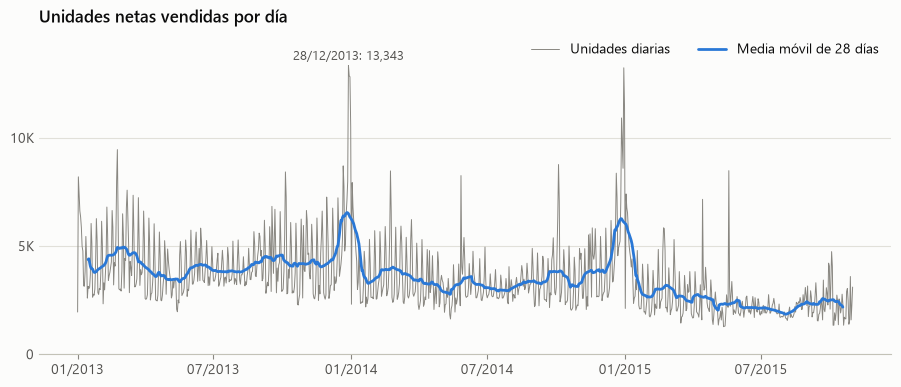

In [45]:
media_28 = diario["unidades"].rolling(28, center=True, min_periods=28).mean()
dia_maximo = diario["unidades"].idxmax()

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(diario.index, diario["unidades"], color=TENUE, linewidth=0.7, label="Unidades diarias")
ax.plot(media_28.index, media_28, color=AZUL, label="Media móvil de 28 días")
etiquetar(ax, dia_maximo, diario["unidades"].max(), f"{dia_maximo:%d/%m/%Y}: {diario['unidades'].max():,.0f}", dy=4)
ax.set_title("Unidades netas vendidas por día")
ax.set_ylim(bottom=0, top=diario["unidades"].max() * 1.12)
eje_y(ax, formato_miles)
eje_fechas(ax)
ax.legend(loc="upper right", ncols=2)
guardar(fig, "6a_ventas_diarias.png")

**Interpretación:** la serie diaria tiene un patrón semanal muy marcado, visible como un serrucho constante. La media móvil de 28 días muestra una caída gradual, de entre 4 y 5 mil unidades diarias a inicios de 2013 a cerca de 2 a 2.5 mil en la segunda mitad de 2015. Destacan dos picos a fin de año, con el máximo de 13,343 unidades el 28 de diciembre de 2013, y también algunos picos aislados fuera de temporada.

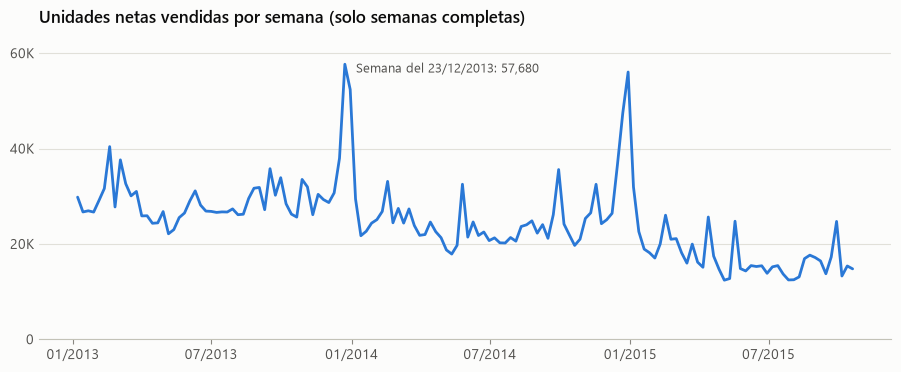

In [46]:
semana_maxima = semanal["unidades"].idxmax()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(semanal.index, semanal["unidades"], color=AZUL)
etiquetar(ax, semana_maxima, semanal["unidades"].max(), f"Semana del {semana_maxima:%d/%m/%Y}: {semanal['unidades'].max():,.0f}", dx=8, dy=-6, ha="left")
ax.set_title("Unidades netas vendidas por semana (solo semanas completas)")
ax.set_ylim(bottom=0, top=semanal["unidades"].max() * 1.12)
eje_y(ax, formato_miles)
eje_fechas(ax)
guardar(fig, "6a_ventas_semanales.png")

**Interpretación:** al agregar por semana desaparece el ciclo intrasemanal y se ve mejor la tendencia descendente. La semana más alta inicia el 23 de diciembre de 2013, con 57,680 unidades, y el pico de fin de 2014 es de magnitud similar, cerca de 56 mil. Se conservan picos puntuales en 2014 y 2015 de hasta 35 mil unidades, que no coinciden con diciembre y requieren revisión por producto.

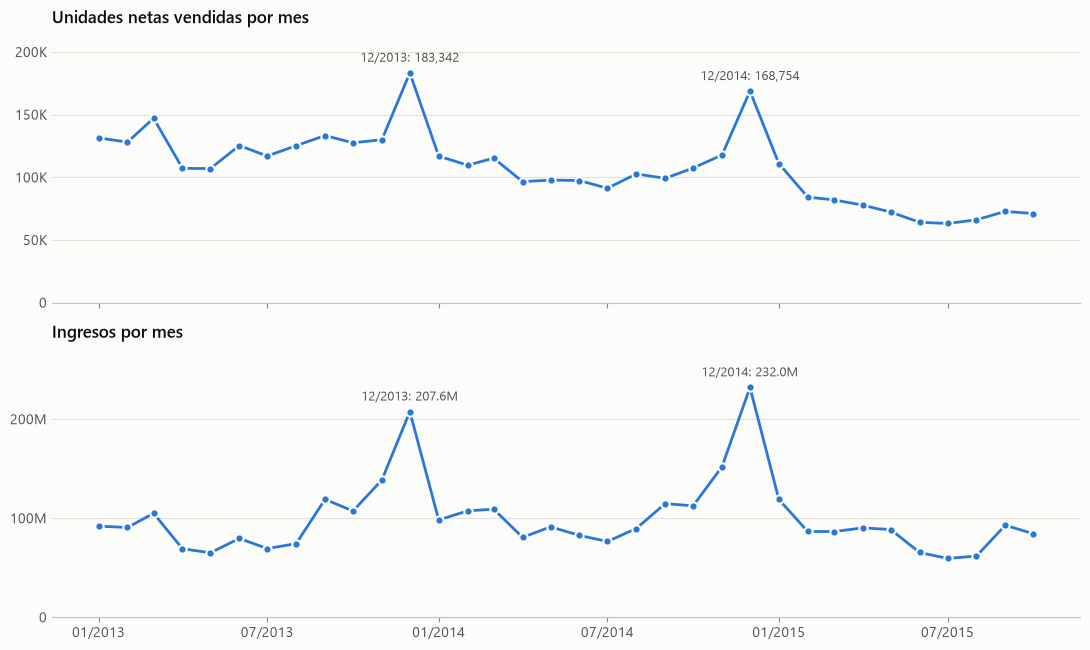

In [47]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.6), sharex=True)
paneles = [
    ("unidades", "Unidades netas vendidas por mes", formato_miles, lambda v: f"{v:,.0f}"),
    ("ingresos", "Ingresos por mes", formato_millones, lambda v: f"{v / 1e6:,.1f}M"),
]
for ax, (columna, titulo, formato, texto) in zip(axes, paneles):
    ax.plot(mensual.index, mensual[columna], color=AZUL, **MARCA)
    for fecha in mensual.index[mensual.index.month == 12]:
        etiquetar(ax, fecha, mensual.loc[fecha, columna], f"{fecha:%m/%Y}: {texto(mensual.loc[fecha, columna])}")
    ax.set_title(titulo)
    ax.set_ylim(bottom=0, top=mensual[columna].max() * 1.18)
    eje_y(ax, formato)
    eje_fechas(ax)
fig.tight_layout()
guardar(fig, "6a_ventas_mensuales.png")

**Interpretación:** la vista mensual resume el comportamiento relevante para el objetivo: una caída sostenida con picos en diciembre. Sin embargo, las unidades y los ingresos divergen: de diciembre de 2013 a diciembre de 2014 las unidades bajan de 183,342 a 168,754 (-8.0%), mientras que los ingresos suben de 207.6 a 232.0 millones (+11.8%). El mínimo de unidades ocurre en julio de 2015, con 63,187, seguido de una ligera recuperación.

### 6.b Patrones temporales

**i y ii. Tendencia y estacionalidad: descomposición de la serie mensual**

In [48]:
unidades_mes = mensual["unidades"].asfreq("MS")
descomposiciones = {
    "aditivo": seasonal_decompose(unidades_mes, model="additive", period=12),
    "multiplicativo": seasonal_decompose(unidades_mes, model="multiplicative", period=12),
}
error_relativo = {
    "aditivo": (descomposiciones["aditivo"].resid.abs() / unidades_mes).mean() * 100,
    "multiplicativo": ((descomposiciones["multiplicativo"].resid - 1).abs()).mean() * 100,
}
modelo = min(error_relativo, key=error_relativo.get)
descomposicion = descomposiciones[modelo]

print(f"Modelo elegido: {modelo}")
print(f"Meses con tendencia estimada: {descomposicion.trend.notna().sum()} de {len(unidades_mes)}")
pd.Series(error_relativo, name="residuo medio (% del valor observado)").round(2).to_frame()

Modelo elegido: aditivo
Meses con tendencia estimada: 22 de 34


,residuo medio (% del valor observado)
aditivo,3.10
multiplicativo,3.73


**Interpretación:** se comparó una descomposición aditiva y una multiplicativa, con un residuo medio de 3.10% y 3.73% del valor observado. Se usa la aditiva, aunque la diferencia es pequeña. La media móvil de 12 meses solo estima la tendencia en 22 de los 34 meses, porque se pierden seis en cada extremo: los últimos seis meses de 2015 quedan sin tendencia estimada.

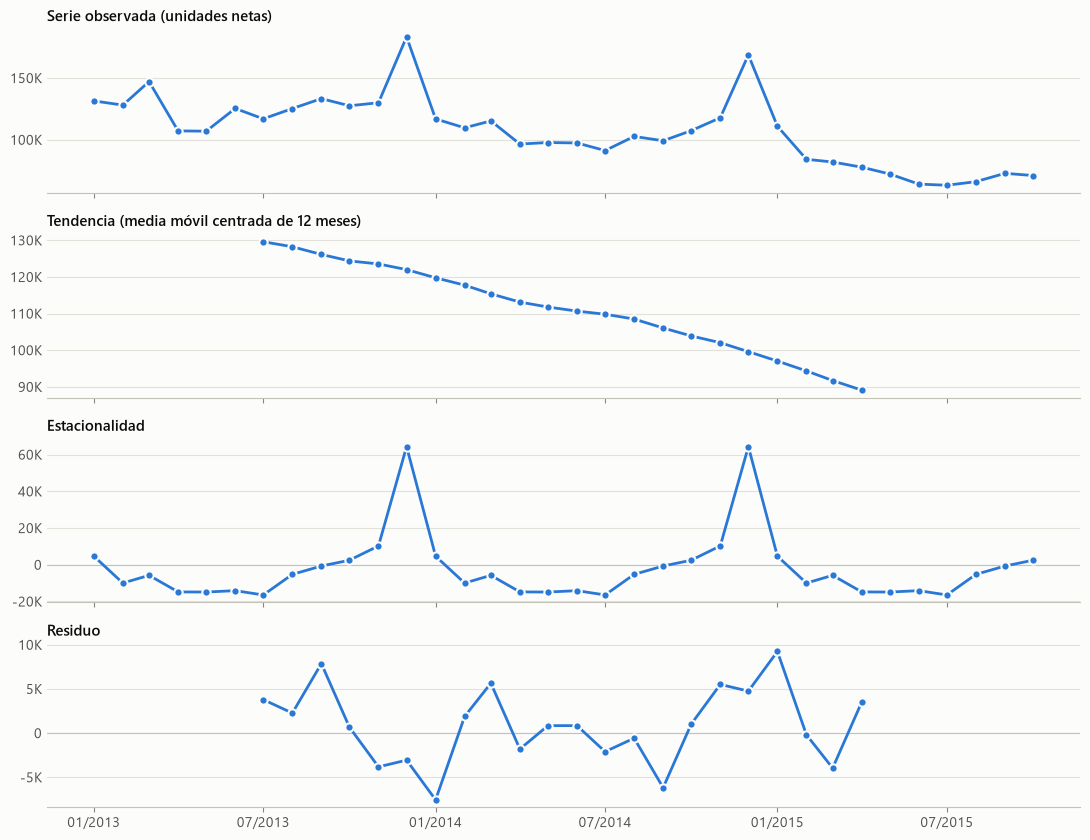

In [49]:
es_aditivo = modelo == "aditivo"
formato_estacional = formato_miles if es_aditivo else FuncFormatter(lambda x, _: f"{x:.1f}")
base_componente = 0 if es_aditivo else 1

fig, axes = plt.subplots(4, 1, figsize=(11, 8.5), sharex=True)
componentes = [
    ("Serie observada (unidades netas)", descomposicion.observed, formato_miles, False),
    ("Tendencia (media móvil centrada de 12 meses)", descomposicion.trend, formato_miles, False),
    ("Estacionalidad", descomposicion.seasonal, formato_estacional, True),
    ("Residuo", descomposicion.resid, formato_estacional, True),
]
for ax, (titulo, serie, formato, con_base) in zip(axes, componentes):
    if con_base:
        ax.axhline(base_componente, color="#c3c2b7", linewidth=0.8)
    ax.plot(serie.index, serie, color=AZUL, **MARCA)
    ax.set_title(f"{titulo}", fontsize=11)
    eje_y(ax, formato)
    eje_fechas(ax)
fig.tight_layout()
guardar(fig, "6b_descomposicion_estacional.png")

**Interpretación:** la tendencia cae casi en línea recta y sin interrupciones. La estacionalidad es clara y dominada por diciembre. Los residuos se mantienen en un rango aproximado de -8 mil a +9 mil unidades, muy por debajo del efecto de diciembre, y los mayores se dan alrededor de enero de 2014 y enero de 2015. Con menos de tres años de datos, cada mes del patrón estacional se estima con muy pocas observaciones, y en particular noviembre y diciembre con solo dos, por lo que debe tomarse con cautela.

In [50]:
tendencia = descomposicion.trend.dropna()
print(f"Tendencia: {tendencia.index[0]:%m/%Y} = {tendencia.iloc[0]:,.0f} | {tendencia.index[-1]:%m/%Y} = {tendencia.iloc[-1]:,.0f} | variación = {(tendencia.iloc[-1] / tendencia.iloc[0] - 1) * 100:.1f}%")

estacional = descomposicion.seasonal.groupby(descomposicion.seasonal.index.month).first()
pd.DataFrame(
    {"mes": MESES, "componente estacional": estacional.round(3 if not es_aditivo else 0).to_numpy()}
).set_index("mes").T

Tendencia: 07/2013 = 129,620 | 04/2015 = 89,114 | variación = -31.3%


mes,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
componente estacional,4674.0,-9965.0,-5758.0,-14785.0,-14856.0,-14101.0,-16449.0,-5224.0,-689.0,2491.0,10271.0,64390.0


**Interpretación:** la tendencia baja de 129,620 unidades en julio de 2013 a 89,114 en abril de 2015, una caída de 31.3%. El componente estacional suma 64,390 unidades en diciembre y 10,271 en noviembre, mientras que los meses más débiles van de abril a julio, con entre -14,101 y -16,449 unidades. Es relevante para el objetivo: noviembre, el mes a predecir, suele quedar por encima de la tendencia, aunque mucho menos que diciembre.

**iii. Picos y caídas abruptas**

In [51]:
cambios = pd.DataFrame(
    {
        "unidades": unidades_mes,
        "mes anterior": unidades_mes.shift(1),
        "cambio": unidades_mes.diff(),
        "cambio %": (unidades_mes.pct_change() * 100).round(1),
    }
).dropna()
cambios.index = cambios.index.strftime("%m/%Y")
pd.concat(
    {"mayores subidas": cambios.nlargest(5, "cambio"), "mayores caídas": cambios.nsmallest(5, "cambio")},
    names=["tipo", "mes"],
).round({"unidades": 0, "mes anterior": 0, "cambio": 0})

unidades  mes anterior   cambio  cambio %
tipo            mes                                               
mayores subidas 12/2013  183342.0      130009.0  53333.0      41.0
                12/2014  168754.0      117845.0  50909.0      43.2
                03/2013  147142.0      128090.0  19052.0      14.9
                06/2013  125381.0      106970.0  18411.0      17.2
                08/2014  102721.0       91279.0  11442.0      12.5
mayores caídas  01/2014  116899.0      183342.0 -66443.0     -36.2
                01/2015  110971.0      168754.0 -57783.0     -34.2
                04/2013  107190.0      147142.0 -39952.0     -27.2
                02/2015   84198.0      110971.0 -26773.0     -24.1
                04/2014   96556.0      115296.0 -18740.0     -16.3

**Interpretación:** los movimientos más grandes son estacionales y se repiten: las dos mayores subidas son diciembre de 2013 (+53,333 unidades, +41.0%) y diciembre de 2014 (+50,909, +43.2%), y las dos mayores caídas son los eneros siguientes (-66,443, -36.2%, y -57,783, -34.2%). Fuera de ese ciclo destacan marzo de 2013 (+14.9%), la caída de abril de 2013 (-27.2%) y la de febrero de 2015 (-24.1%).

In [52]:
diario["día"] = diario.index.day_of_week.map(dict(enumerate(DIAS)))
diario["mediana móvil 29 días"] = diario["unidades"].rolling(29, center=True, min_periods=15).median()
diario["veces la mediana móvil"] = (diario["unidades"] / diario["mediana móvil 29 días"]).round(2)

diario.nlargest(10, "unidades")[["día", "unidades", "ingresos", "mediana móvil 29 días", "veces la mediana móvil"]].round({"unidades": 0, "ingresos": 0, "mediana móvil 29 días": 0})

,día,unidades,ingresos,mediana móvil 29 días,veces la mediana móvil
date,,,,,
2013-12-28,Sáb,13343.0,14626701.0,5806.0,2.30
2014-12-30,Mar,13236.0,17002645.0,5070.0,2.61
2013-12-29,Dom,12863.0,14273758.0,5368.0,2.40
2013-12-30,Lun,12823.0,14671056.0,5301.0,2.42
2014-12-31,Mié,11393.0,15021005.0,5070.0,2.25
2014-12-27,Sáb,10919.0,15649898.0,5227.0,2.09
2013-12-31,Mar,10514.0,12115056.0,5301.0,1.98
2014-12-28,Dom,9727.0,12455894.0,5070.0,1.92
2013-02-23,Sáb,9456.0,6817895.0,4337.0,2.18


**Interpretación:** ocho de los diez días con más ventas caen entre el 27 y el 31 de diciembre, lo que muestra que el pico anual se concentra en los últimos días del año, con unas 2 a 2.6 veces la mediana de su entorno. Los otros dos son sábados: el 23 de febrero de 2013, fecha festiva en Rusia, y el 4 de octubre de 2014.

In [53]:
diario.nlargest(10, "veces la mediana móvil")[["día", "unidades", "mediana móvil 29 días", "veces la mediana móvil"]]

,día,unidades,mediana móvil 29 días,veces la mediana móvil
date,,,,
2015-05-19,Mar,8483.0,1997.0,4.25
2015-04-14,Mar,7158.0,2299.0,3.11
2014-05-27,Mar,8256.0,3010.0,2.74
2014-12-30,Mar,13236.0,5070.0,2.61
2014-02-22,Sáb,8472.0,3263.0,2.60
2014-10-04,Sáb,8767.0,3583.0,2.45
2013-12-30,Lun,12823.0,5301.0,2.42
2013-12-29,Dom,12863.0,5368.0,2.40
2013-12-28,Sáb,13343.0,5806.0,2.30


**Interpretación:** al medir contra la mediana del entorno aparecen picos que el ranking absoluto oculta. El mayor es el martes 19 de mayo de 2015, con 8,483 unidades, 4.25 veces lo normal en ese periodo, seguido del 14 de abril de 2015 (3.11 veces) y el 27 de mayo de 2014 (2.74 veces). Son martes, un día normalmente flojo, fuera de la temporada navideña. Estos datos no explican la causa, y conviene identificar en la sección 7 qué productos o tiendas los generan.

**iv. Ciclos por día de la semana y por mes del año**

In [54]:
por_dia = (
    diario.assign(año=diario.index.year, dia_num=diario.index.day_of_week)
    .pivot_table(index="dia_num", columns="año", values="unidades", aggfunc="mean")
)
por_dia.index = DIAS
por_dia.index.name = "día"
indice_dia = por_dia / por_dia.mean() * 100

pd.concat({"unidades promedio por día": por_dia.round(0), "índice (promedio del año = 100)": indice_dia.round(1)}, axis=1)

unidades promedio por día                 índice (promedio del año = 100)              
año                      2013    2014    2015                            2013   2014   2015
día                                                                                        
Lun                    3256.0  2771.0  2049.0                            76.0   76.5   81.5
Mar                    3574.0  3127.0  2394.0                            83.4   86.4   95.2
Mié                    3538.0  3035.0  2207.0                            82.6   83.8   87.8
Jue                    3708.0  3232.0  2131.0                            86.6   89.3   84.8
Vie                    4603.0  3807.0  2639.0                           107.5  105.2  105.0
Sáb                    6160.0  5144.0  3338.0                           143.8  142.1  132.8
Dom                    5146.0  4227.0  2835.0                           120.1  116.7  112.8

**Interpretación:** el ciclo semanal es consistente en los tres años. El sábado es el mejor día (6,160, 5,144 y 3,338 unidades promedio) y el lunes el más débil en índice (76.0, 76.5 y 81.5). De viernes a domingo se vende por encima del promedio y de lunes a jueves por debajo. Se usa el promedio porque no todos los años tienen el mismo número de cada día. En 2015 el patrón se aplana un poco: el sábado baja a un índice de 132.8, y el martes sube a 95.2, lo que coincide con los picos en martes de ese año.

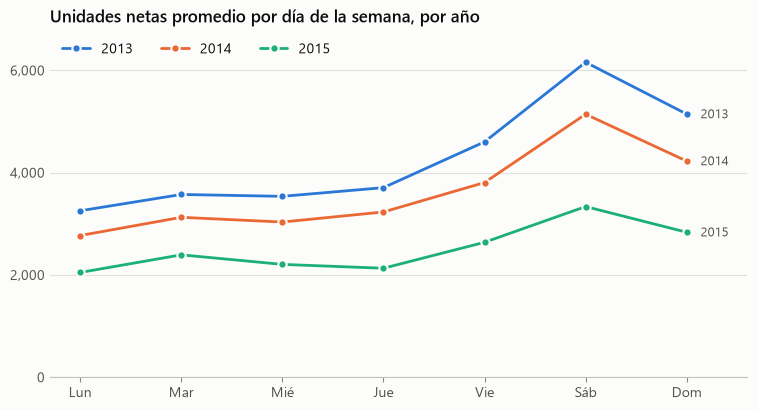

In [55]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for anio, color in COLOR_ANIO.items():
    ax.plot(DIAS, por_dia[anio], color=color, label=str(anio), **MARCA)
    etiquetar(ax, 6, por_dia.loc["Dom", anio], str(anio), dx=10, dy=-3, ha="left")
ax.set_title("Unidades netas promedio por día de la semana, por año")
ax.set_ylim(bottom=0, top=por_dia.max().max() * 1.1)
ax.set_xlim(-0.3, 6.6)
eje_y(ax, formato_entero)
ax.legend(loc="upper left", ncols=3)
guardar(fig, "6b_patron_dia_semana.png")

**Interpretación:** las tres curvas tienen casi la misma forma, con un ascenso desde el jueves, máximo el sábado y descenso el domingo. Las líneas no se cruzan y cada año queda por debajo del anterior, de modo que la caída afecta a toda la semana y no a días específicos.

In [56]:
por_mes = mensual.assign(año=mensual.index.year, mes_num=mensual.index.month).pivot_table(
    index="mes_num", columns="año", values="unidades", aggfunc="sum"
)
por_mes["var % 2014 vs 2013"] = ((por_mes[2014] / por_mes[2013] - 1) * 100).round(1)
por_mes["var % 2015 vs 2014"] = ((por_mes[2015] / por_mes[2014] - 1) * 100).round(1)
por_mes.index = MESES
por_mes.index.name = "mes"
por_mes.round(1)

año,2013,2014,2015,var % 2014 vs 2013,var % 2015 vs 2014
mes,,,,,
Ene,131478.0,116899.0,110971.0,-11.1,-5.1
Feb,128090.0,109686.0,84198.0,-14.4,-23.2
Mar,147142.0,115296.0,82014.0,-21.6,-28.9
Abr,107190.0,96556.0,77827.0,-9.9,-19.4
May,106970.0,97789.0,72295.0,-8.6,-26.1
Jun,125381.0,97429.0,64114.0,-22.3,-34.2
Jul,116966.0,91279.0,63187.0,-22.0,-30.8
Ago,125291.0,102721.0,66079.0,-18.0,-35.7
Sep,133332.0,99208.0,72843.0,-25.6,-26.6


**Interpretación:** todos los meses caen frente al mismo mes del año anterior: de -8.0% (diciembre) a -25.6% (septiembre) en 2014, y de -5.1% (enero) a -35.7% (agosto) en 2015. La caída es mayor en 2015 en los diez meses disponibles. Para el mes objetivo, noviembre superó a octubre en 1.9% en 2013 y en 9.7% en 2014, sobre un octubre de 2015 de 71,056 unidades. Es una referencia útil, pero solo se basa en dos años.

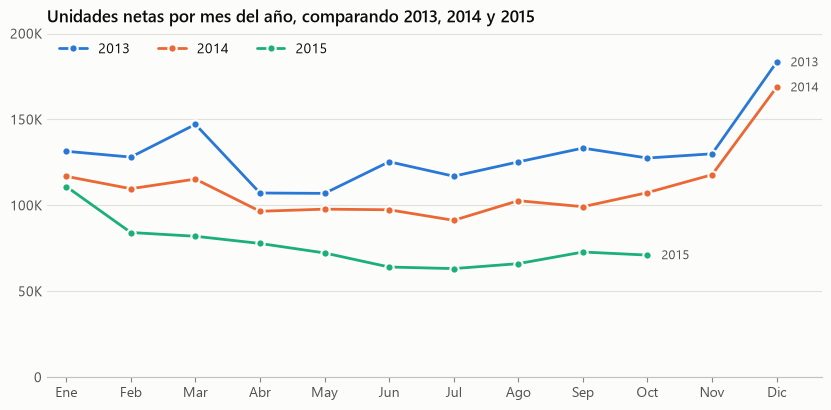

In [57]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for anio, color in COLOR_ANIO.items():
    serie = por_mes[anio].dropna()
    ax.plot(serie.index, serie, color=color, label=str(anio), **MARCA)
    etiquetar(ax, len(serie) - 1, serie.iloc[-1], str(anio), dx=10, dy=-3, ha="left")
ax.set_title("Unidades netas por mes del año, comparando 2013, 2014 y 2015")
ax.set_ylim(bottom=0, top=por_mes[[2013, 2014, 2015]].max().max() * 1.1)
ax.set_xlim(-0.3, 11.7)
eje_y(ax, formato_miles)
ax.legend(loc="upper left", ncols=3)
guardar(fig, "6b_patron_mes_anio.png")

**Interpretación:** el salto de diciembre se repite en 2013 y 2014, con forma muy parecida, y 2015 queda por debajo en todos los meses, sin datos de noviembre y diciembre. En 2013 destaca marzo, con 147,142 unidades, un máximo que no se repite con la misma fuerza en 2014 ni en 2015. A mediados de año se observa el tramo más débil, más acusado en 2015, con el mínimo en julio.

## 7. Análisis comparativo entre sucursales y productos

### 7.a Productos y categorías más y menos vendidos

In [58]:
def extremos(tabla, metrica, columnas, n=10):
    orden = tabla.sort_values(metrica, ascending=False, kind="stable")
    resultado = pd.concat({f"top {n}": orden.head(n)[columnas], f"bottom {n}": orden.tail(n)[columnas]}, names=["grupo"])
    return resultado.astype({"unidades": "int64", "ingresos": "int64"})


columnas_producto = ["item_name", "item_category_name", "unidades", "ingresos", "transacciones"]
extremos(por_producto, "unidades", columnas_producto)

item_name                        item_category_name  unidades   ingresos  transacciones
grupo     item_id                                                                                                                                 
top 10    20949    Фирменный пакет майка 1С Интерес белый (34*42)...  Подарки - Сумки, Альбомы, Коврики д/мыши    187642     928863          31340
          2808                Diablo III [PC, Jewel, русская версия]             Игры PC - Стандартные издания     17245   16852778           7479
          3732            Grand Theft Auto V [PS3, русские субтитры]                                Игры - PS3     16642   43617975           6475
          17717                 Прием денежных средств для 1С-Онлайн                                 Служебные     15830   17200825           9067
          5822     Playstation Store пополнение бумажника: Карта ...                        Карты оплаты - PSN     14515   15408983           9408
          3734       Grand Theft Auto V [Xbox 360, русские субтитры]                           Игры - XBOX 360     11688   31065160           5805
          6675     Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...                     Игровые консоли - PS4     10289  219391488           5122
          3731             Grand Theft Auto V [PC, русские субтитры]             Игры PC - Стандартные издания     10099   19983482           2354
          1855                    Battlefield 4 [PC, русская версия]             Игры PC - Стандартные издания     10032    9357024           5681
          16787                    Одни из нас [PS3, русская версия]                                Игры - PS3      9227   21907839           5283
bottom 10 22161                     ЯРОСЛАВ. ТЫСЯЧУ ЛЕТ НАЗАД э (BD)                            Кино - Blu-Ray         1         58              1
          22169                        Яйцо дракона (Игра престолов)                        Подарки - Сувениры         1       4349              1
          4591                 MCCARTNEY, PAUL In Red Square (Фирм.)                Музыка - Музыкальное видео         0          0              2
          7547                VideoStudio Pro X6 IE Windows Mini-Box              Программы - Для дома и офиса         0          0              2
          8515                  Английский язык. 2 - 5 класс (Jewel)                     Программы - Обучающие         0         14              2
          13477    Комплект «Sony PS3 (320 Gb) (CECH-3008B)» + иг...                     Игровые консоли - PS3         0      -7592              2
          11871                                                 Змея          Подарки - Гаджеты, роботы, спорт        -1      -5999              1
          13474    Комплект «Sony PS3 (320 Gb) (CECH-2508B) + игр...                     Игровые консоли - PS3        -1     -10398              1
          18062                                       Робопет Собака          Подарки - Гаджеты, роботы, спорт        -1      -4999              1
          1590     Assassin’s Creed 3. Freedom Edition [PC, русск...           Игры PC - Коллекционные издания       -11     -28589              8

**Interpretación:** en la parte alta domina la bolsa 20949 (187,642 unidades), seguida de videojuegos como Diablo III y Grand Theft Auto V, además del servicio 17717 y una tarjeta de PlayStation Store. En la parte baja hay productos con una unidad o con saldo negativo. El caso más bajo es `Assassin's Creed 3. Freedom Edition`, con -11 unidades en 8 transacciones. Hay muchos productos empatados con pocas unidades, de modo que el bottom 10 es una muestra de esa cola y no una lista única.

In [59]:
extremos(por_producto, "ingresos", columnas_producto)

item_name                item_category_name  unidades   ingresos  transacciones
grupo     item_id                                                                                                                         
top 10    6675     Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...             Игровые консоли - PS4     10289  219391488           5122
          3732            Grand Theft Auto V [PS3, русские субтитры]                        Игры - PS3     16642   43617975           6475
          13443    Комплект Sony PS4 (500 Gb) Black (CUH-1108A/B0...             Игровые консоли - PS4      1366   34331245            850
          3734       Grand Theft Auto V [Xbox 360, русские субтитры]                   Игры - XBOX 360     11688   31065160           5805
          3733            Grand Theft Auto V [PS4, русские субтитры]                        Игры - PS4      6506   22298864           2299
          16787                    Одни из нас [PS3, русская версия]                        Игры - PS3      9227   21907839           5283
          3731             Grand Theft Auto V [PC, русские субтитры]     Игры PC - Стандартные издания     10099   19983482           2354
          13405    Комплект "Microsoft Xbox One 500GB (Day One Ed...        Игровые консоли - XBOX ONE       991   18125479            673
          17717                 Прием денежных средств для 1С-Онлайн                         Служебные     15830   17200825           9067
          5823     Playstation Store пополнение бумажника: Карта ...                Карты оплаты - PSN      6523   17151846           4974
bottom 10 8515                  Английский язык. 2 - 5 класс (Jewel)             Программы - Обучающие         0         14              2
          22010              Щелкунчик и Крысиный король [PC, Jewel]     Игры PC - Стандартные издания         1         14              1
          22098                     Элемент питания КОСМОС LR03 2*BL                  Элементы питания         1          7              1
          4591                 MCCARTNEY, PAUL In Red Square (Фирм.)        Музыка - Музыкальное видео         0          0              2
          7547                VideoStudio Pro X6 IE Windows Mini-Box      Программы - Для дома и офиса         0          0              2
          18062                                       Робопет Собака  Подарки - Гаджеты, роботы, спорт        -1      -4999              1
          11871                                                 Змея  Подарки - Гаджеты, роботы, спорт        -1      -5999              1
          13477    Комплект «Sony PS3 (320 Gb) (CECH-3008B)» + иг...             Игровые консоли - PS3         0      -7592              2
          13474    Комплект «Sony PS3 (320 Gb) (CECH-2508B) + игр...             Игровые консоли - PS3        -1     -10398              1
          1590     Assassin’s Creed 3. Freedom Edition [PC, русск...   Игры PC - Коллекционные издания       -11     -28589              8

**Interpretación:** por ingresos lidera la consola PS4 (producto 6675), con 219.4 millones, seguida de versiones de Grand Theft Auto V y paquetes de consolas. La parte baja incluye productos con ingresos casi nulos o negativos, entre -28,589 y 14. Productos como las consolas PS3 en paquete aparecen con ingresos negativos porque en el histórico pesan más sus devoluciones que sus ventas.

In [60]:
netos_no_positivos = por_producto[por_producto["unidades"] <= 0].sort_values("unidades")
print(f"Productos con ventas netas <= 0: {len(netos_no_positivos)} de {len(por_producto):,} vendidos")
print(f"Productos del catálogo sin ninguna transacción: {items['item_id'].nunique() - len(por_producto)}")
netos_no_positivos[columnas_producto].astype({"unidades": "int64", "ingresos": "int64"})

Productos con ventas netas <= 0: 8 de 21,807 vendidos
Productos del catálogo sin ninguna transacción: 363


,item_name,item_category_name,unidades,ingresos,transacciones
item_id,,,,,
1590,"Assassin’s Creed 3. Freedom Edition [PC, русск...",Игры PC - Коллекционные издания,-11,-28589,8
18062,Робопет Собака,"Подарки - Гаджеты, роботы, спорт",-1,-4999,1
13474,Комплект «Sony PS3 (320 Gb) (CECH-2508B) + игр...,Игровые консоли - PS3,-1,-10398,1
11871,Змея,"Подарки - Гаджеты, роботы, спорт",-1,-5999,1
8515,Английский язык. 2 - 5 класс (Jewel),Программы - Обучающие,0,14,2
7547,VideoStudio Pro X6 IE Windows Mini-Box,Программы - Для дома и офиса,0,0,2
4591,"MCCARTNEY, PAUL In Red Square (Фирм.)",Музыка - Музыкальное видео,0,0,2
13477,Комплект «Sony PS3 (320 Gb) (CECH-3008B)» + иг...,Игровые консоли - PS3,0,-7592,2


**Interpretación:** 8 de los 21,807 productos vendidos tienen ventas netas menores o iguales a cero: cuatro con saldo 0 y cuatro negativos (tres con -1 y uno con -11). Es un grupo mínimo. Un saldo negativo puede deberse a ventas anteriores a enero de 2013, que el histórico no incluye. Además, 363 productos del catálogo no tienen ninguna transacción.

In [61]:
columnas_categoria = ["unidades", "ingresos", "productos", "% unidades", "% ingresos"]
extremos(por_categoria, "unidades", columnas_categoria)

unidades   ingresos  productos  % unidades  % ingresos
grupo     item_category_name                                                                              
top 10    Кино - DVD                                  634170  169944072       4964       17.38        5.00
          Игры PC - Стандартные издания               456540  257519291        751       12.51        7.58
          Музыка - CD локального производства         348591  100022563       2327        9.56        2.94
          Игры - PS3                                  254887  412052780        625        6.99       12.12
          Кино - Blu-Ray                              203283   90478232       1777        5.57        2.66
          Подарки - Сумки, Альбомы, Коврики д/мыши    187998     934206          6        5.15        0.03
          Игры PC - Дополнительные издания            174954  136419148        235        4.80        4.01
          Игры - XBOX 360                             169940  259615132        496        4.66        7.64
          Игры - PS4                                  127319  373010312        157        3.49       10.97
          Подарки - Настольные игры (компактные)       73077   24727890        151        2.00        0.73
bottom 10 Игры - PS2                                      11       3828          6        0.00        0.00
          Игры MAC - Цифра                                 8       5422          7        0.00        0.00
          Книги - Компьютерная литература                  6       1654          5        0.00        0.00
          PC - Гарнитуры/Наушники                          3        263          3        0.00        0.00
          Книги - Открытки                                 3         58          2        0.00        0.00
          Книги - Путеводители                             3        300          3        0.00        0.00
          Книги - Художественная литература                3        847          3        0.00        0.00
          Аксессуары - PS2                                 2        431          2        0.00        0.00
          Игровые консоли - PS2                            1       1998          1        0.00        0.00
          Книги - Познавательная литература                1        129          1        0.00        0.00

**Interpretación:** `Кино - DVD` (17.38%), `Игры PC - Стандартные издания` (12.51%) y `Музыка - CD локального производства` (9.56%) concentran casi 40% de las unidades. El otro extremo son categorías casi sin movimiento, como las de PS2 (`Игровые консоли - PS2`, con 1 unidad) y varias de libros. Son catálogos residuales o marginales, con muy poca información para el modelo.

In [62]:
extremos(por_categoria, "ingresos", columnas_categoria)

unidades   ingresos  productos  % unidades  % ingresos
grupo     item_category_name                                                                         
top 10    Игры - PS3                             254887  412052780        625        6.99       12.12
          Игры - PS4                             127319  373010312        157        3.49       10.97
          Игровые консоли - PS4                   13230  292239761         17        0.36        8.60
          Игры - XBOX 360                        169940  259615132        496        4.66        7.64
          Игры PC - Стандартные издания          456540  257519291        751       12.51        7.58
          Кино - DVD                             634170  169944072       4964       17.38        5.00
          Игры PC - Дополнительные издания       174954  136419148        235        4.80        4.01
          Музыка - CD локального производства    348591  100022563       2327        9.56        2.94
          Кино - Blu-Ray                         203283   90478232       1777        5.57        2.66
          Программы - Для дома и офиса            48224   87085926        275        1.32        2.56
bottom 10 Книги - Бизнес литература                  15       4502         12        0.00        0.00
          Игры - PS2                                 11       3828          6        0.00        0.00
          Игровые консоли - PS2                       1       1998          1        0.00        0.00
          Книги - Компьютерная литература             6       1654          5        0.00        0.00
          Книги - Художественная литература           3        847          3        0.00        0.00
          Аксессуары - PS2                            2        431          2        0.00        0.00
          Книги - Путеводители                        3        300          3        0.00        0.00
          PC - Гарнитуры/Наушники                     3        263          3        0.00        0.00
          Книги - Познавательная литература           1        129          1        0.00        0.00
          Книги - Открытки                            3         58          2        0.00        0.00

**Interpretación:** el orden por ingresos favorece a las categorías caras: `Игры - PS3` (12.12%), `Игры - PS4` (10.97%) e `Игровые консоли - PS4`, que con 0.36% de las unidades genera 8.60% de los ingresos. `Кино - DVD`, primera en unidades, baja al sexto lugar. Las categorías con menos ingresos coinciden en gran parte con las de menos unidades.

### 7.b Comparación entre tiendas

El dataset no identifica tickets de compra, así que el **ticket promedio** se aproxima como ingreso por transacción (fila de `sales_train`).

In [63]:
comparacion_tiendas = ventas.groupby(["shop_id", "shop_name"]).agg(
    unidades=("item_cnt_day", "sum"),
    ingresos=("revenue", "sum"),
    transacciones=("item_cnt_day", "size"),
    meses_activos=("date_block_num", "nunique"),
).reset_index("shop_name")
comparacion_tiendas["unidades por mes activo"] = comparacion_tiendas["unidades"] / comparacion_tiendas["meses_activos"]
comparacion_tiendas["ingresos por mes activo"] = comparacion_tiendas["ingresos"] / comparacion_tiendas["meses_activos"]
comparacion_tiendas["ticket promedio"] = comparacion_tiendas["ingresos"] / comparacion_tiendas["transacciones"]

comparacion_tiendas.sort_values("unidades", ascending=False).astype(
    {"unidades": "int64", "ingresos": "int64", "unidades por mes activo": "int64", "ingresos por mes activo": "int64", "ticket promedio": "int64"}
)

,shop_name,unidades,ingresos,transacciones,meses_activos,unidades por mes activo,ingresos por mes activo,ticket promedio
shop_id,,,,,,,,
31,"Москва ТЦ ""Семеновский""",310777,235217019,235636,34,9140,6918147,998
25,"Москва ТРК ""Атриум""",241919,216479572,186103,34,7115,6367046,1163
54,"Химки ТЦ ""Мега""",185789,141939523,143479,28,6635,5069268,989
28,"Москва ТЦ ""МЕГА Теплый Стан"" II",184557,159746337,142234,34,5428,4698421,1123
57,"Якутск Орджоникидзе, 56",152812,119637153,127285,34,4494,3518739,939
42,"СПб ТК ""Невский Центр""",144933,151916533,109252,34,4262,4468133,1390
27,"Москва ТЦ ""МЕГА Белая Дача II""",136657,140632474,105366,32,4270,4394764,1334
6,"Воронеж (Плехановская, 13)",100489,98067453,82663,34,2955,2884336,1186
58,"Якутск ТЦ ""Центральный""",88045,71975824,77119,34,2589,2116936,933


**Interpretación:** la tienda 31 lidera en unidades (310,777), seguida de la 25 y la 54. Los totales penalizan a las tiendas con historia corta, por lo que conviene leer también las unidades por mes activo: por ejemplo, la tienda 30, con solo 26 meses, vende 2,339 unidades por mes, más que la 46 (2,323), que es décima por total. El ticket promedio de la mayoría de las tiendas se ubica entre unos 900 y 1,600.

In [64]:
columnas_ranking = ["shop_name", "unidades", "meses_activos", "unidades por mes activo", "ticket promedio"]
pd.concat(
    {
        "más unidades por mes activo": comparacion_tiendas.nlargest(5, "unidades por mes activo")[columnas_ranking],
        "menos unidades por mes activo": comparacion_tiendas.nsmallest(5, "unidades por mes activo")[columnas_ranking],
        "mayor ticket promedio": comparacion_tiendas.nlargest(5, "ticket promedio")[columnas_ranking],
        "menor ticket promedio": comparacion_tiendas.nsmallest(5, "ticket promedio")[columnas_ranking],
    },
    names=["criterio"],
).astype({"unidades": "int64", "unidades por mes activo": "int64", "ticket promedio": "int64"})

shop_name  unidades  meses_activos  unidades por mes activo  ticket promedio
criterio                      shop_id                                                                                                                    
más unidades por mes activo   31                               Москва ТЦ "Семеновский"    310777             34                     9140              998
                              25                                   Москва ТРК "Атриум"    241919             34                     7115             1163
                              54                                       Химки ТЦ "Мега"    185789             28                     6635              989
                              28                       Москва ТЦ "МЕГА Теплый Стан" II    184557             34                     5428             1123
                              57                               Якутск Орджоникидзе, 56    152812             34                     4494              939
menos unidades por mes activo 36                 Новосибирск ТРЦ "Галерея Новосибирск"       330              1                      330             1234
                              34                                  Н.Новгород ТРЦ "РИО"      6451             16                      403             1492
                              40       РостовНаДону ТРК "Мегацентр Горизонт" Островной      4943             11                      449             1008
                              33                                     Мытищи ТРК "XL-3"      5482              9                      609             1183
                              10                            Жуковский ул. Чкалова 39м?     25095             34                      738              910
mayor ticket promedio         9                                      Выездная Торговля     15866              4                     3966             4364
                              20                                   Москва "Распродажа"      5872              2                     2936             3682
                              12                                   Интернет-магазин ЧС     73478             34                     2161             3234
                              2                                       Адыгея ТЦ "Мега"     30620             34                      900             1694
                              43                                       СПб ТК "Сенная"     50608             25                     2024             1583
menor ticket promedio         13                                   Казань ТЦ "Бехетле"     19763             20                      988              336
                              51                             Тюмень ТЦ "Зеленый Берег"     48767             33                     1477              544
                              8                           Воронеж ТРЦ Сити-Парк "Град"      3595              4                      898              688
                              32                            Москва ТЦ "Серебряный Дом"      8781              7                     1254              726
                              23                      Москва ТК "Буденовский" (пав.А2)      7705              4                     1926              807

**Interpretación:** las tiendas 31, 25 y 54 también lideran por unidades por mes activo, así que su ventaja no se debe solo a llevar más tiempo abiertas. Los tickets más altos corresponden a canales especiales: 9 (`Выездная Торговля`, 4,364), 20 (`Распродажа`, 3,682) y 12 (tienda en línea, 3,234). Los más bajos son 13 (336) y 51 (544), muy por debajo del resto. La aproximación del ticket por fila no refleja compras con varios productos, de modo que estos valores sirven para comparar tiendas, no para conocer el gasto real por cliente.

### 7.c Outliers y comportamientos anómalos

**Percentiles y regla del rango intercuartílico**

In [65]:
percentiles = [0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999, 0.99999, 1]
tabla_percentiles = sales[["item_price", "item_cnt_day"]].quantile(percentiles)
tabla_percentiles.index = [f"p{p * 100:g}" for p in percentiles]

for columna in ("item_price", "item_cnt_day"):
    q1, q3 = sales[columna].quantile([0.25, 0.75])
    limite = q3 + 1.5 * (q3 - q1)
    n_fuera = (sales[columna] > limite).sum()
    print(f"{columna}: Q1 = {q1:,.2f}, Q3 = {q3:,.2f}, límite superior IQR = {limite:,.2f}, filas por encima = {n_fuera:,} ({n_fuera / len(sales) * 100:.2f}%)")
tabla_percentiles

item_price: Q1 = 249.00, Q3 = 999.00, límite superior IQR = 2,124.00, filas por encima = 258,943 (8.82%)
item_cnt_day: Q1 = 1.00, Q3 = 1.00, límite superior IQR = 1.00, filas por encima = 299,121 (10.19%)


,item_price,item_cnt_day
p50,399.0,1.00000
p75,999.0,1.00000
p90,1999.0,2.00000
p95,2690.0,2.00000
p99,5999.0,5.00000
p99.9,23990.0,22.00000
p99.99,29990.0,67.00000
p99.999,35300.0,241.28316
p100,307980.0,2169.00000


**Interpretación:** los valores crecen de forma moderada hasta percentiles muy altos y luego saltan. El precio pasa de 35,300 en el percentil 99.999 a un máximo de 307,980, y la cantidad de 241 a 2,169. La regla del rango intercuartílico no sirve aquí: marcaría 8.82% de los precios y, como Q1 y Q3 de la cantidad valen 1, marcaría como atípica cualquier venta de más de una unidad (10.19% de las filas). Por eso el umbral se define revisando las transacciones concretas.

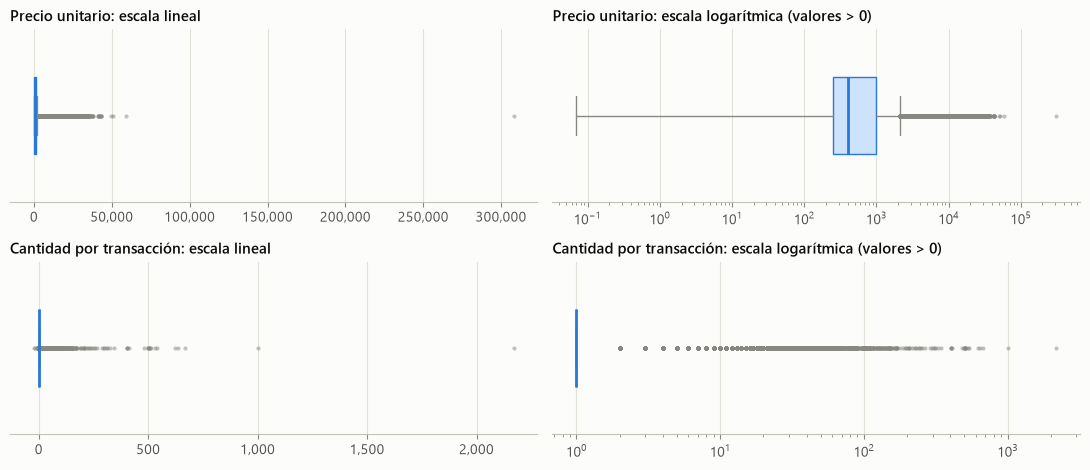

In [66]:
fig, axes = plt.subplots(2, 2, figsize=(11, 4.8))
paneles_box = [
    ("item_price", "Precio unitario", sales["item_price"]),
    ("item_cnt_day", "Cantidad por transacción", sales["item_cnt_day"]),
]
estilo_box = {
    "orientation": "horizontal",
    "widths": 0.45,
    "patch_artist": True,
    "boxprops": {"facecolor": "#cde2fb", "edgecolor": AZUL},
    "medianprops": {"color": AZUL, "linewidth": 2},
    "whiskerprops": {"color": TENUE},
    "capprops": {"color": TENUE},
    "flierprops": {"marker": "o", "markersize": 3, "markerfacecolor": TENUE, "markeredgecolor": "none", "alpha": 0.5},
}
for fila, (_, titulo, serie) in zip(axes, paneles_box):
    fila[0].boxplot(serie.to_numpy(), **estilo_box)
    fila[0].set_title(f"{titulo}: escala lineal", fontsize=11)
    fila[1].boxplot(serie[serie > 0].to_numpy(), **estilo_box)
    fila[1].set_xscale("log")
    fila[1].set_title(f"{titulo}: escala logarítmica (valores > 0)", fontsize=11)
    fila[0].xaxis.set_major_formatter(formato_entero)
    for ax in fila:
        ax.set_yticks([])
        ax.grid(False)
        ax.xaxis.grid(True)
fig.tight_layout()
guardar(fig, "7c_boxplots_outliers.png")

**Interpretación:** en escala lineal casi toda la distribución queda aplastada contra cero, y un único precio cercano a 308 mil y una cantidad cercana a 2,200 quedan separados del resto. En escala logarítmica el precio muestra una caja clara entre 249 y 999, con una cola continua hasta unas decenas de miles, y un punto aislado. La cantidad no forma caja porque casi todas las ventas son de una unidad. La cola no es en sí un error, y solo los puntos separados requieren revisión.

**Transacciones más extremas**

In [67]:
columnas_extremas = ["date", "shop_id", "shop_name", "item_id", "item_name", "item_category_name", "item_price", "item_cnt_day", "revenue"]
transacciones_producto = ventas.groupby("item_id").size()
precio_mediano_producto = ventas.groupby("item_id")["item_price"].median()

extremos_precio = ventas.nlargest(10, "item_price")[columnas_extremas].copy()
extremos_precio["precio mediano del producto"] = extremos_precio["item_id"].map(precio_mediano_producto)
extremos_precio["transacciones del producto"] = extremos_precio["item_id"].map(transacciones_producto)
extremos_precio

,date,shop_id,shop_name,item_id,item_name,item_category_name,item_price,item_cnt_day,revenue,precio mediano del producto,transacciones del producto
1163157,2013-12-13,12,Интернет-магазин ЧС,6066,Radmin 3 - 522 лиц.,Программы - Для дома и офиса,307980.0,1.0,307980.0,307980.00,1
885137,2013-09-17,12,Интернет-магазин ЧС,11365,Доставка (EMS),Доставка товара,59200.0,1.0,59200.0,1203.75,242
1488133,2014-03-20,25,"Москва ТРК ""Атриум""",13199,Коллекционные шахматы (Властелин Колец),Подарки - Сувениры,50999.0,1.0,50999.0,50999.00,1
2327153,2015-01-29,12,Интернет-магазин ЧС,7241,UserGate Proxy & Firewall 6.X с модулем фильтр...,Программы - Для дома и офиса,49782.0,1.0,49782.0,49782.00,1
2885686,2015-10-23,42,"СПб ТК ""Невский Центр""",13403,"Комплект ""Microsoft Xbox One 1TB Limited Edit...",Игровые консоли - XBOX ONE,42990.0,1.0,42990.0,41990.00,12
2910150,2015-10-29,12,Интернет-магазин ЧС,13403,"Комплект ""Microsoft Xbox One 1TB Limited Edit...",Игровые консоли - XBOX ONE,42990.0,1.0,42990.0,41990.00,12
2917754,2015-10-20,3,"Балашиха ТРК ""Октябрь-Киномир""",13403,"Комплект ""Microsoft Xbox One 1TB Limited Edit...",Игровые консоли - XBOX ONE,42990.0,1.0,42990.0,41990.00,12
2931374,2015-10-20,22,Москва Магазин С21,13403,"Комплект ""Microsoft Xbox One 1TB Limited Edit...",Игровые консоли - XBOX ONE,42990.0,1.0,42990.0,41990.00,12
1006637,2013-10-24,12,Интернет-магазин ЧС,7238,UserGate Proxy & Firewall 6.X до 100 сессий,Программы - Для дома и офиса,42000.0,1.0,42000.0,42000.00,1
2893094,2015-10-20,38,"Омск ТЦ ""Мега""",13403,"Комплект ""Microsoft Xbox One 1TB Limited Edit...",Игровые консоли - XBOX ONE,41990.0,1.0,41990.0,41990.00,12


**Interpretación:** el precio máximo (307,980) es `Radmin 3 - 522 лиц.`, un paquete de 522 licencias vendido una sola vez en la tienda en línea: es una venta corporativa, no un precio típico. El siguiente valor es 59,200, un cargo `Доставка (EMS)` cuya mediana es 1,203.75. Los demás, entre 42 y 51 mil, son artículos caros coherentes con su precio mediano, como el paquete de Xbox One o unas piezas de ajedrez de colección, por lo que parecen legítimos.

In [68]:
cantidad_mediana_producto = ventas.groupby("item_id")["item_cnt_day"].median()

extremos_cantidad = ventas.nlargest(10, "item_cnt_day")[columnas_extremas].copy()
extremos_cantidad["cantidad mediana del producto"] = extremos_cantidad["item_id"].map(cantidad_mediana_producto)
extremos_cantidad["transacciones del producto"] = extremos_cantidad["item_id"].map(transacciones_producto)
extremos_cantidad

,date,shop_id,shop_name,item_id,item_name,item_category_name,item_price,item_cnt_day,revenue,cantidad mediana del producto,transacciones del producto
2909812,2015-10-28,12,Интернет-магазин ЧС,11373,Доставка до пункта выдачи (Boxberry),Доставка товара,0.908714,2169.0,1.971000e+03,4.0,464
2326924,2015-01-15,12,Интернет-магазин ЧС,20949,Фирменный пакет майка 1С Интерес белый (34*42)...,"Подарки - Сумки, Альбомы, Коврики д/мыши",4.000000,1000.0,4.000000e+03,3.0,31340
2864229,2015-09-30,12,Интернет-магазин ЧС,9248,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) [...",Служебные - Билеты,1692.526158,669.0,1.132300e+06,2.0,61
2851085,2015-09-30,55,Цифровой склад 1С-Онлайн,9249,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) У...",Билеты (Цифра),1702.825746,637.0,1.084700e+06,2.0,61
2608034,2015-04-14,12,Интернет-магазин ЧС,3731,"Grand Theft Auto V [PC, русские субтитры]",Игры PC - Стандартные издания,1904.548077,624.0,1.188438e+06,1.0,2354
2626175,2015-05-19,12,Интернет-магазин ЧС,11373,Доставка до пункта выдачи (Boxberry),Доставка товара,155.192950,539.0,8.364900e+04,4.0,464
2851067,2015-09-29,55,Цифровой склад 1С-Онлайн,9249,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) У...",Билеты (Цифра),1500.000000,533.0,7.995000e+05,2.0,61
2048513,2014-10-02,12,Интернет-магазин ЧС,9242,"Билет ""ИгроМир 2014"" (на один день (отдельно -...",Билеты (Цифра),1500.000000,512.0,7.680000e+05,3.0,635
2067664,2014-10-09,55,Цифровой склад 1С-Онлайн,19437,"Средиземье: Тени Мордора [PC, Цифровая версия]",Игры PC - Цифра,899.000000,508.0,4.566920e+05,2.0,33
2864254,2015-09-29,12,Интернет-магазин ЧС,9248,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) [...",Служебные - Билеты,1500.000000,504.0,7.560000e+05,2.0,61


**Interpretación:** las diez mayores cantidades ocurren en los canales 12 (tienda en línea) y 55 (almacén digital). La mayor, 2,169 unidades el 28 de octubre de 2015, es un servicio de entrega con un precio de 0.91, muy distinto a su uso normal (mediana de 4 unidades). La segunda son exactamente 1,000 bolsas, cuando la mediana es 3, lo que parece un movimiento por lote. Las siguientes, de 669 hacia abajo, son entradas a la feria ИгроМир, videojuegos y un servicio de entrega en días de alta demanda, y corresponden a una actividad comercial real.

In [69]:
total_unidades = ventas["item_cnt_day"].sum()
total_ingresos = ventas["revenue"].sum()


def impacto(mascara, descripcion):
    return {
        "condición": descripcion,
        "filas": int(mascara.sum()),
        "productos": ventas.loc[mascara, "item_id"].nunique(),
        "% unidades": round(ventas.loc[mascara, "item_cnt_day"].sum() / total_unidades * 100, 4),
        "% ingresos": round(ventas.loc[mascara, "revenue"].sum() / total_ingresos * 100, 4),
    }


pd.DataFrame(
    [impacto(ventas["item_price"] > u, f"item_price > {u:,}") for u in (20000, 50000, 100000, 200000)]
    + [impacto(ventas["item_cnt_day"] >= u, f"item_cnt_day >= {u:,}") for u in (100, 200, 500, 1000, 2000)]
).set_index("condición")

,filas,productos,% unidades,% ingresos
condición,,,,
"item_price > 20,000",6781,50,0.2550,6.7339
"item_price > 50,000",3,3,0.0001,0.0123
"item_price > 100,000",1,1,0.0000,0.0091
"item_price > 200,000",1,1,0.0000,0.0091
item_cnt_day >= 100,151,51,0.8558,1.1203
item_cnt_day >= 200,39,17,0.4645,0.4073
item_cnt_day >= 500,14,8,0.2658,0.2025
"item_cnt_day >= 1,000",2,2,0.0869,0.0002
"item_cnt_day >= 2,000",1,1,0.0595,0.0001


**Interpretación:** un corte de precio en 20,000 eliminaría 6,781 filas y 6.73% de los ingresos, porque incluye consolas legítimas, y sería excesivo. Por encima de 100,000 solo queda 1 fila. En cantidad, recortar desde 100 unidades quitaría cerca de 0.86% de las unidades, incluidos lanzamientos reales, mientras que desde 1,000 solo afecta a 2 filas. Los cortes altos aíslan únicamente los casos separados del resto.

**Investigación de los picos fuera de temporada**

In [70]:
primera_venta_producto = ventas[ventas["item_cnt_day"] > 0].groupby("item_id")["date"].min()


def analizar_pico(fecha, clave, n=8):
    dia = pd.Timestamp(fecha)
    previos = ventas[(ventas["date"] >= dia - pd.Timedelta(days=28)) & (ventas["date"] < dia)]
    base = previos.groupby(clave)["item_cnt_day"].sum() / 28
    actual = ventas[ventas["date"] == dia].groupby(clave)["item_cnt_day"].sum()
    resultado = pd.DataFrame({"unidades del día": actual}).join(base.rename("promedio 28 días previos")).fillna(0)
    resultado["exceso"] = resultado["unidades del día"] - resultado["promedio 28 días previos"]
    exceso_total = resultado["exceso"].sum()
    resultado["% del exceso"] = (resultado["exceso"] / exceso_total * 100).round(1)
    return resultado.sort_values("exceso", ascending=False).head(n).round(1), actual.sum(), exceso_total


pico_items, unidades_pico, exceso_pico = analizar_pico("2015-05-19", "item_id")
pico_items = pico_items.join(items.set_index("item_id")["item_name"]).join(primera_venta_producto.rename("primera venta"))
print(f"Unidades del 19/05/2015: {unidades_pico:,.0f} | exceso sobre los 28 días previos: {exceso_pico:,.0f}")
pico_items

Unidades del 19/05/2015: 8,483 | exceso sobre los 28 días previos: 7,358


,unidades del día,promedio 28 días previos,exceso,% del exceso,item_name,primera venta
item_id,,,,,,
10209,2005.0,5.6,1999.4,27.2,"Ведьмак 3: Дикая охота [PC, русская версия]",2015-05-18
10210,1804.0,7.7,1796.3,24.4,"Ведьмак 3: Дикая охота [PS4, русская версия]",2015-05-18
11373,539.0,3.3,535.7,7.3,Доставка до пункта выдачи (Boxberry),2013-01-08
10212,458.0,1.4,456.6,6.2,Ведьмак 3: Дикая охота. Коллекционное издание ...,2015-05-18
11370,343.0,3.7,339.3,4.6,Доставка (по Москве),2013-01-10
10207,334.0,0.6,333.4,4.5,"Ведьмак 3: Дикая охота [PC, Jewel, русская вер...",2015-05-18
10213,253.0,1.0,252.0,3.4,Ведьмак 3: Дикая охота. Коллекционное издание ...,2015-05-18
20949,325.0,112.4,212.6,2.9,Фирменный пакет майка 1С Интерес белый (34*42)...,2013-04-24


**Interpretación:** el pico del 19 de mayo de 2015 se explica por el lanzamiento de `Ведьмак 3: Дикая охота` (The Witcher 3), que coincide con su estreno mundial. Las cinco ediciones de la lista suman 65.7% del exceso de 7,358 unidades, y sus primeras ventas en el histórico son del 18 de mayo. Los servicios de entrega (11373 y 11370) aportan otro 11.9%, lo que apunta a pedidos enviados a domicilio o a puntos de recogida.

In [71]:
pico_tiendas, _, _ = analizar_pico("2015-05-19", "shop_name", n=6)
pico_grupos, _, _ = analizar_pico("2015-05-19", "item_category_name", n=6)
display(pico_tiendas)
pico_grupos

,unidades del día,promedio 28 días previos,exceso,% del exceso
shop_name,,,,
Интернет-магазин ЧС,2228.0,38.8,2189.2,34.0
"СПб ТК ""Невский Центр""",740.0,114.4,625.6,9.7
"Москва ТРК ""Атриум""",535.0,160.5,374.5,5.8
"Москва ТЦ ""Семеновский""",514.0,192.5,321.5,5.0
"Воронеж (Плехановская, 13)",321.0,44.3,276.7,4.3
Москва Магазин С21,238.0,36.4,201.6,3.1


,unidades del día,promedio 28 días previos,exceso,% del exceso
item_category_name,,,,
Игры - PS4,2187.0,112.4,2074.6,32.2
Игры PC - Дополнительные издания,2060.0,59.0,2001.0,31.0
Доставка товара,1234.0,11.4,1222.6,19.0
Игры PC - Коллекционные издания,462.0,4.6,457.4,7.1
Игры PC - Стандартные издания,529.0,256.8,272.2,4.2
"Подарки - Сумки, Альбомы, Коврики д/мыши",325.0,112.4,212.6,3.3


**Interpretación:** la tienda en línea concentra 34.0% del exceso, con 2,228 unidades frente a un promedio previo de 38.8, seguida de tiendas físicas grandes. Por categoría pesan `Игры - PS4` (32.2%), `Игры PC - Дополнительные издания` (31.0%) y `Доставка товара` (19.0%). Es un evento de lanzamiento con fuerte componente en línea, no un error de registro.

In [72]:
filas_otros_picos = []
for fecha in ("2015-04-14", "2014-05-27"):
    tabla, unidades_dia, exceso_dia = analizar_pico(fecha, "item_id", n=3)
    tabla = tabla.join(items.set_index("item_id")["item_name"]).join(primera_venta_producto.rename("primera venta"))
    tabla.insert(0, "fecha del pico", fecha)
    filas_otros_picos.append(tabla)
pd.concat(filas_otros_picos)

,fecha del pico,unidades del día,promedio 28 días previos,exceso,% del exceso,item_name,primera venta
item_id,,,,,,,
3731,2015-04-14,3825.0,0.0,3825.0,65.2,"Grand Theft Auto V [PC, русские субтитры]",2015-04-14
4894,2015-04-14,758.0,0.0,758.0,12.9,"Mortal Kombat X [PS4, русские субтитры]",2015-04-14
20949,2015-04-14,519.0,77.3,441.7,7.5,Фирменный пакет майка 1С Интерес белый (34*42)...,2013-04-24
7807,2014-05-27,1426.0,0.0,1426.0,21.8,"Watch_Dogs. Специальное издание [PS4, русская ...",2014-05-27
7805,2014-05-27,1051.0,0.0,1051.0,16.1,"Watch_Dogs. Специальное издание [PC, русская в...",2014-05-27
7794,2014-05-27,570.0,0.0,570.0,8.7,"Watch_Dogs. Dedsec Edition [PC, русская версия]",2014-05-27


**Interpretación:** los otros dos picos en martes tienen la misma causa. El 14 de abril de 2015 se lanzó Grand Theft Auto V para PC (65.2% del exceso) y coincidió con Mortal Kombat X en PS4 (12.9%). El 27 de mayo de 2014 fue el lanzamiento de Watch_Dogs. En ambos casos la primera venta registrada es ese mismo día. Estos picos son demanda real, por lo que no se eliminan, y muestran que la fecha de lanzamiento será una variable importante para el modelo.

**Umbral para eliminar transacciones extremas**

In [73]:
UMBRAL_PRECIO = 100_000
UMBRAL_CANTIDAD = 1_000

mascara_extrema = (ventas["item_price"] > UMBRAL_PRECIO) | (ventas["item_cnt_day"] >= UMBRAL_CANTIDAD)
eliminadas = ventas.loc[mascara_extrema, columnas_extremas]
filas_antes, unidades_antes_umbral, ingresos_antes_umbral = len(ventas), ventas["item_cnt_day"].sum(), ventas["revenue"].sum()

ventas = ventas[~mascara_extrema].copy()
sales = sales[~((sales["item_price"] > UMBRAL_PRECIO) | (sales["item_cnt_day"] >= UMBRAL_CANTIDAD))]
tablas["sales_train"] = sales

print(f"Filas: {filas_antes:,} -> {len(ventas):,} (eliminadas: {filas_antes - len(ventas)}) | sales_train: {len(sales):,}")
print(f"Unidades eliminadas: {unidades_antes_umbral - ventas['item_cnt_day'].sum():,.0f} ({(1 - ventas['item_cnt_day'].sum() / unidades_antes_umbral) * 100:.3f}%)")
print(f"Ingresos eliminados: {ingresos_antes_umbral - ventas['revenue'].sum():,.0f} ({(1 - ventas['revenue'].sum() / ingresos_antes_umbral) * 100:.3f}%)")
eliminadas

Filas: 2,935,843 -> 2,935,840 (eliminadas: 3) | sales_train: 2,935,840
Unidades eliminadas: 3,170 (0.087%)
Ingresos eliminados: 313,951 (0.009%)


,date,shop_id,shop_name,item_id,item_name,item_category_name,item_price,item_cnt_day,revenue
1163157,2013-12-13,12,Интернет-магазин ЧС,6066,Radmin 3 - 522 лиц.,Программы - Для дома и офиса,307980.000000,1.0,307980.0
2326924,2015-01-15,12,Интернет-магазин ЧС,20949,Фирменный пакет майка 1С Интерес белый (34*42)...,"Подарки - Сумки, Альбомы, Коврики д/мыши",4.000000,1000.0,4000.0
2909812,2015-10-28,12,Интернет-магазин ЧС,11373,Доставка до пункта выдачи (Boxberry),Доставка товара,0.908714,2169.0,1971.0


**Interpretación y decisión:** se eliminan las transacciones con `item_price > 100,000` o `item_cnt_day >= 1,000`, que son 3 filas: las licencias Radmin, el cargo de entrega de 2,169 unidades y el lote de 1,000 bolsas. Justificación: los tres valores están separados del resto de la distribución (el siguiente precio es 59,200 y la siguiente cantidad 669), y ninguno representa demanda normal de consumidores. Las ventas altas de lanzamientos y entradas quedan por debajo del umbral y se conservan. El efecto es mínimo en ingresos (0.009%) y en unidades (0.087%), pero evita distorsionar el objetivo: la entrega de octubre de 2015 habría inflado el último mes del histórico, justo antes del mes a predecir. Las secciones 5 y 6 se calcularon antes de este corte.

**Tiendas con comportamiento anómalo**

In [74]:
MES_FINAL = 33
MINIMO_MESES = 12

vida_tiendas = ventas.groupby("shop_id").agg(
    primer_mes=("date_block_num", "min"),
    ultimo_mes=("date_block_num", "max"),
    meses_activos=("date_block_num", "nunique"),
    unidades=("item_cnt_day", "sum"),
)
vida_tiendas["huecos"] = vida_tiendas["ultimo_mes"] - vida_tiendas["primer_mes"] + 1 - vida_tiendas["meses_activos"]
vida_tiendas["en_test"] = vida_tiendas.index.isin(test["shop_id"].unique())
vida_tiendas["abre_tarde"] = vida_tiendas["primer_mes"] > 0
vida_tiendas["cierra"] = vida_tiendas["ultimo_mes"] < MES_FINAL
vida_tiendas["pocos_meses"] = vida_tiendas["meses_activos"] < MINIMO_MESES
vida_tiendas["intermitente"] = vida_tiendas["huecos"] > 0
vida_tiendas = vida_tiendas.join(shops.set_index("shop_id")["shop_name"])

marcas = ["abre_tarde", "cierra", "pocos_meses", "intermitente"]
anomalas = vida_tiendas[vida_tiendas[marcas].any(axis=1)].sort_values(["en_test", "meses_activos"])
anomalas["unidades"] = anomalas["unidades"].astype("int64")
anomalas[["shop_name", "primer_mes", "ultimo_mes", "meses_activos", "huecos", "unidades", "en_test"] + marcas]

,shop_name,primer_mes,ultimo_mes,meses_activos,huecos,unidades,en_test,abre_tarde,cierra,pocos_meses,intermitente
shop_id,,,,,,,,,,,
20,"Москва ""Распродажа""",21,33,2,11,5872,False,True,False,True,True
8,"Воронеж ТРЦ Сити-Парк ""Град""",0,3,4,0,3595,False,False,True,True,False
9,Выездная Торговля,9,33,4,21,15866,False,True,False,True,True
23,"Москва ТК ""Буденовский"" (пав.А2)",0,3,4,0,7705,False,False,True,True,False
32,"Москва ТЦ ""Серебряный Дом""",0,6,7,0,8781,False,False,True,True,False
33,"Мытищи ТРК ""XL-3""",19,27,9,0,5482,False,True,True,True,False
40,"РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",14,24,11,0,4943,False,True,True,True,False
13,"Казань ТЦ ""Бехетле""",0,19,20,0,19763,False,False,True,False,False
17,"Красноярск ТЦ ""Взлетка Плаза""",5,24,20,0,25838,False,True,True,False,False


**Interpretación:** 22 de las 57 tiendas muestran algún comportamiento irregular. Las tiendas 8, 23, 32, 33 y 40 operan menos de 12 meses y cierran. Las tiendas 9 y 20 son canales eventuales con grandes huecos: la 20 solo vende en octubre de 2014 y octubre de 2015. Entre las que cierran hay tiendas importantes, como la 54, tercera en unidades, que deja de vender en el mes 27, y la 27, que termina en el mes 32. La tienda 36 solo tiene un mes de ventas, octubre de 2015, y sí está en `test`.

In [75]:
def contar(mascara):
    return {"tiendas": int(mascara.sum()), "IDs": sorted(int(i) for i in vida_tiendas.index[mascara])}


pd.DataFrame(
    {
        "total": contar(pd.Series(True, index=vida_tiendas.index)),
        "en test": contar(vida_tiendas["en_test"]),
        "no están en test": contar(~vida_tiendas["en_test"]),
        "en test y activas en octubre de 2015": contar(vida_tiendas["en_test"] & (vida_tiendas["ultimo_mes"] == MES_FINAL)),
        "en test con menos de 12 meses": contar(vida_tiendas["en_test"] & vida_tiendas["pocos_meses"]),
        "en test y abren tarde": contar(vida_tiendas["en_test"] & vida_tiendas["abre_tarde"]),
        "en test con huecos": contar(vida_tiendas["en_test"] & vida_tiendas["intermitente"]),
        "cierran y no están en test": contar(vida_tiendas["cierra"] & ~vida_tiendas["en_test"]),
    }
).T

,tiendas,IDs
total,57,"[2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 1..."
en test,42,"[2, 3, 4, 5, 6, 7, 10, 12, 14, 15, 16, 18, 19,..."
no están en test,15,"[8, 9, 13, 17, 20, 23, 27, 29, 30, 32, 33, 40,..."
en test y activas en octubre de 2015,42,"[2, 3, 4, 5, 6, 7, 10, 12, 14, 15, 16, 18, 19,..."
en test con menos de 12 meses,1,[36]
en test y abren tarde,7,"[5, 34, 36, 39, 48, 49, 55]"
en test con huecos,0,[]
cierran y no están en test,13,"[8, 13, 17, 23, 27, 29, 30, 32, 33, 40, 43, 51..."


**Interpretación:** las 42 tiendas de `test` están activas en octubre de 2015 y ninguna tiene huecos, lo que resulta favorable para el modelo. Siete abren después del inicio y solo la tienda 36 tiene menos de 12 meses de historia: será la más difícil de predecir, con un único mes como referencia. De las 15 que no están en `test`, 13 cerraron y las otras dos (9 y 20) son canales eventuales. Es decir, `test` solo incluye tiendas en operación. Sus datos históricos aún pueden aportar información sobre productos, pero sus series no se predicen.

## 8. Visualizaciones clave

Estas gráficas usan los datos ya limpios: sección 4 y umbral de 7.c.

### 8.a Serie de tiempo de ventas totales

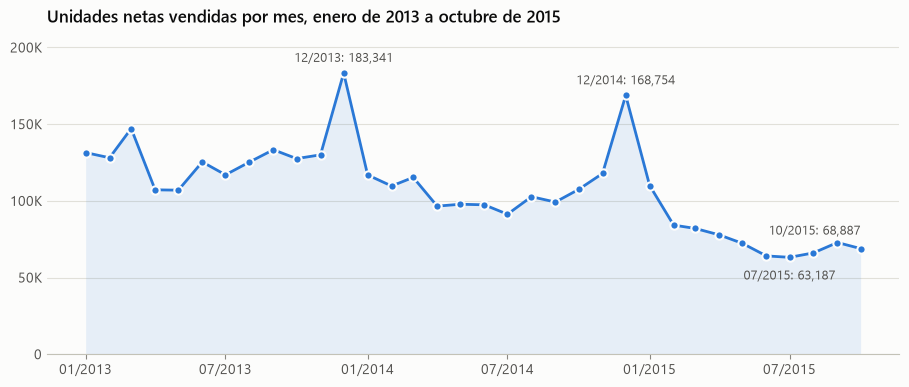

In [76]:
serie_total = ventas.groupby(ventas["date"].dt.to_period("M"))["item_cnt_day"].sum()
serie_total.index = serie_total.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(serie_total.index, serie_total, color=AZUL, **MARCA)
ax.fill_between(serie_total.index, serie_total, color=AZUL, alpha=0.1, linewidth=0)
for fecha, dy, ha in [(serie_total.index[serie_total.index.month == 12][0], 8, "center"), (serie_total.index[serie_total.index.month == 12][1], 8, "center"), (serie_total.idxmin(), -16, "center"), (serie_total.index[-1], 10, "right")]:
    etiquetar(ax, fecha, serie_total[fecha], f"{fecha:%m/%Y}: {serie_total[fecha]:,.0f}", dy=dy, ha=ha)
ax.set_title("Unidades netas vendidas por mes, enero de 2013 a octubre de 2015")
ax.set_ylim(bottom=0, top=serie_total.max() * 1.15)
eje_y(ax, formato_miles)
eje_fechas(ax)
guardar(fig, "8a_serie_ventas_totales.png")

**Interpretación:** la serie total muestra los tres rasgos principales: caída sostenida, picos en diciembre de 2013 (183,341 unidades) y diciembre de 2014 (168,754), y mínimo en julio de 2015 (63,187). Tras eliminar las transacciones extremas, octubre de 2015 queda en 68,887 unidades, en lugar de 71,056. Ese es el punto de partida más limpio para predecir noviembre de 2015.

### 8.b Ventas por tienda

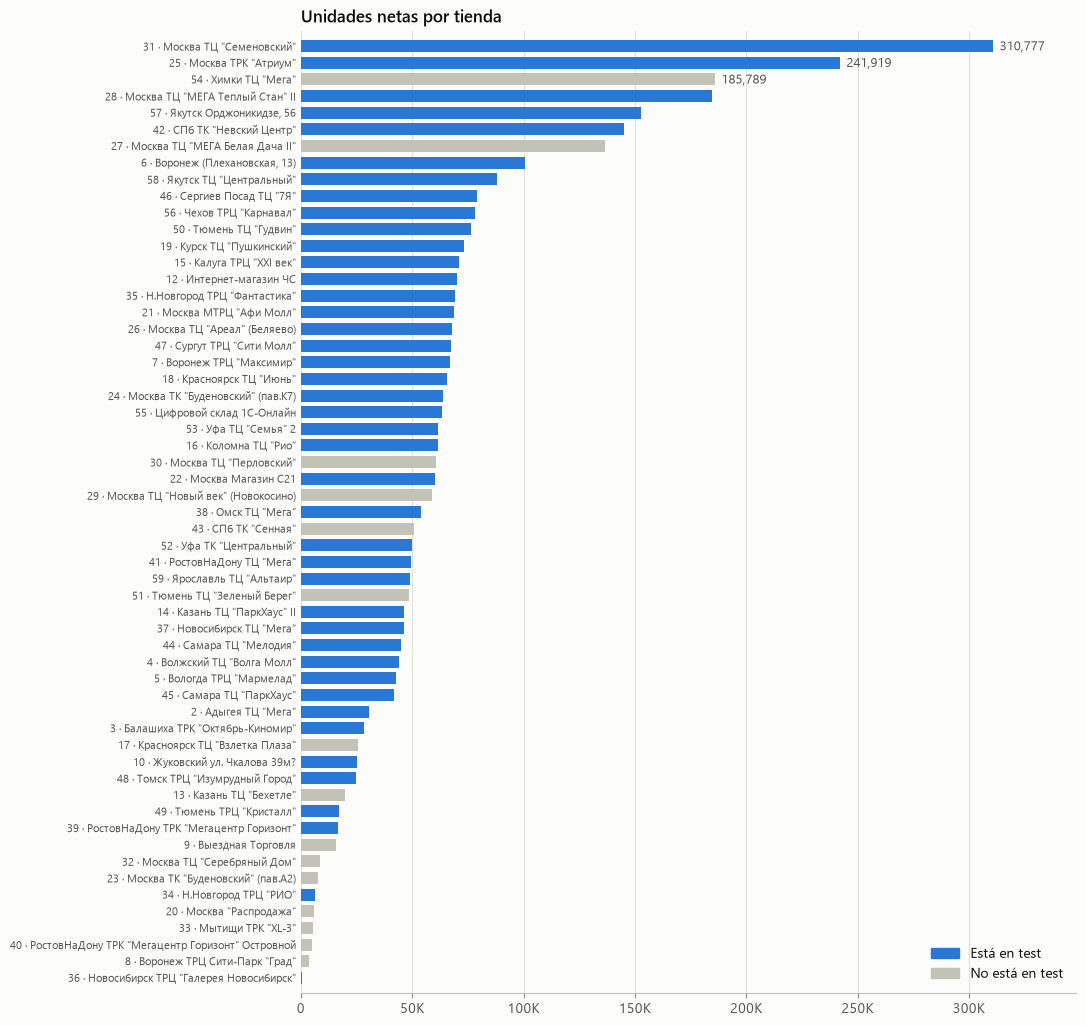

In [77]:
from matplotlib.patches import Patch

tiendas_barras = ventas.groupby(["shop_id", "shop_name"])["item_cnt_day"].sum().reset_index().sort_values("item_cnt_day")
GRIS_BARRA = "#c3c2b7"
ids_test = set(test["shop_id"])
colores_tienda = [AZUL if tienda in ids_test else GRIS_BARRA for tienda in tiendas_barras["shop_id"]]
etiquetas_tienda = [f"{tienda} · {nombre[:50]}" for tienda, nombre in zip(tiendas_barras["shop_id"], tiendas_barras["shop_name"])]

fig, ax = plt.subplots(figsize=(10, 12.5))
ax.barh(etiquetas_tienda, tiendas_barras["item_cnt_day"], color=colores_tienda, height=0.72)
for posicion, valor in list(enumerate(tiendas_barras["item_cnt_day"]))[-3:]:
    etiquetar(ax, valor, posicion, f"{valor:,.0f}", dx=5, dy=-3, ha="left")
ax.set_title("Unidades netas por tienda")
ax.grid(False)
ax.xaxis.grid(True)
ax.set_xlim(right=tiendas_barras["item_cnt_day"].max() * 1.12)
ax.margins(y=0.01)
ax.xaxis.set_major_formatter(formato_miles)
ax.tick_params(axis="y", labelsize=8, length=0)
ax.legend(handles=[Patch(color=AZUL, label="Está en test"), Patch(color=GRIS_BARRA, label="No está en test")], loc="lower right")
guardar(fig, "8b_barras_tiendas.png")

**Interpretación:** las ventas se concentran en pocas tiendas: 31 y 25 destacan claramente, y la mayoría vende entre unas 40 y 80 mil unidades en total. Las tiendas en gris no están en `test`, y entre ellas hay algunas grandes, como la 54 y la 27. Las tiendas con menos unidades suelen tener una historia corta, como la 36, por lo que este total debe leerse junto con los meses activos de 7.b.

### 8.c Top 20 de productos y ventas por categoría

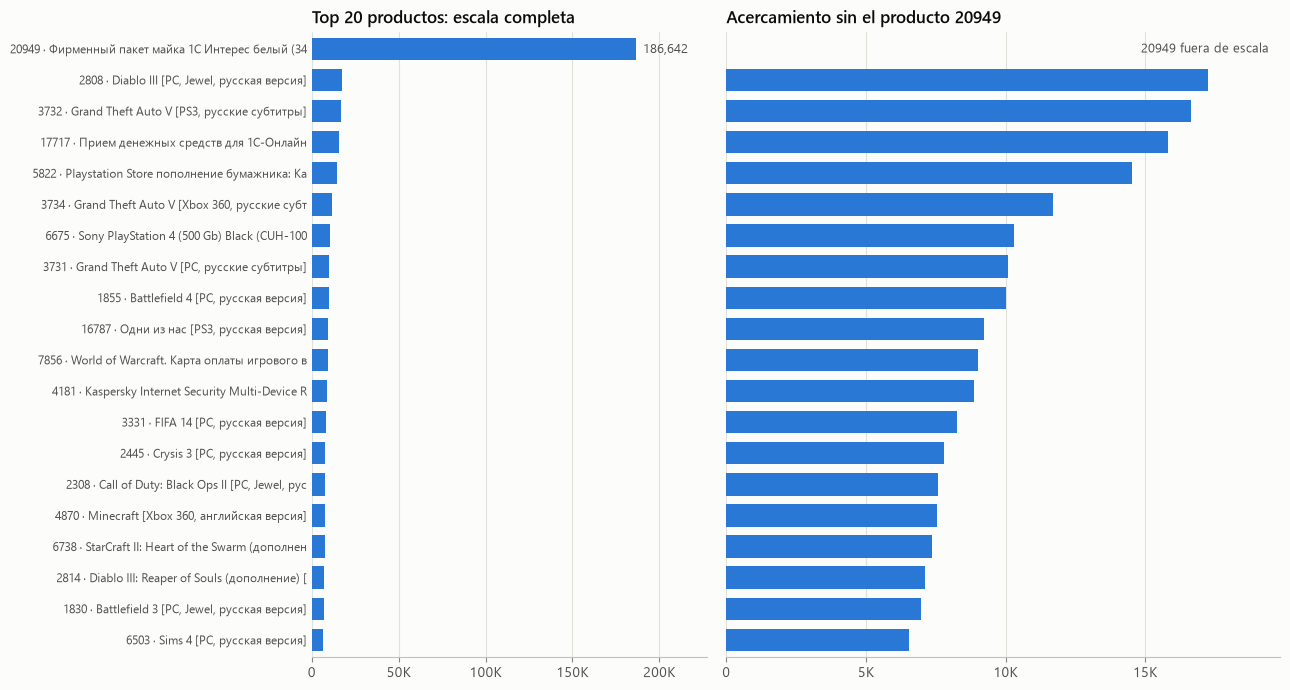

In [78]:
from matplotlib.ticker import MultipleLocator

top20 = (
    ventas.groupby("item_id")["item_cnt_day"].sum().nlargest(20).to_frame("unidades")
    .join(items.set_index("item_id")["item_name"])
    .iloc[::-1]
)
etiquetas_producto = [f"{item} · {nombre.strip()[:42]}" for item, nombre in zip(top20.index, top20["item_name"])]
limite_zoom = top20["unidades"].iloc[:-1].max() * 1.15

fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True, gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].barh(etiquetas_producto, top20["unidades"], color=AZUL, height=0.72)
axes[0].set_title("Top 20 productos: escala completa")
axes[0].xaxis.set_major_formatter(formato_miles)
axes[1].barh(etiquetas_producto[:-1], top20["unidades"].iloc[:-1], color=AZUL, height=0.72)
axes[1].set_title("Acercamiento sin el producto 20949")
axes[1].set_xlim(0, limite_zoom)
axes[1].xaxis.set_major_formatter(formato_miles)
etiquetar(axes[0], top20["unidades"].iloc[-1], 19, f"{top20['unidades'].iloc[-1]:,.0f}", dx=5, dy=-3, ha="left")
axes[0].set_xlim(0, top20["unidades"].iloc[-1] * 1.22)
axes[0].xaxis.set_major_locator(MultipleLocator(50000))
axes[1].xaxis.set_major_locator(MultipleLocator(5000))
axes[1].text(limite_zoom * 0.98, 19, f"20949 fuera de escala", ha="right", va="center", fontsize=9, color=TINTA_SECUNDARIA)
for ax in axes:
    ax.grid(False)
    ax.xaxis.grid(True)
    ax.margins(y=0.01)
    ax.tick_params(axis="y", labelsize=8.5, length=0)
fig.tight_layout()
guardar(fig, "8c_barras_top20_productos.png")

**Interpretación:** en la escala completa la bolsa 20949 casi anula a los demás productos, de modo que el acercamiento permite compararlos: van de unas 17 mil a 6.6 mil unidades y son principalmente videojuegos de PC y consola, junto con tarjetas de pago y un antivirus. El liderazgo de esta bolsa refleja un artículo complementario, que probablemente acompaña a otras compras, no un producto principal de la demanda.

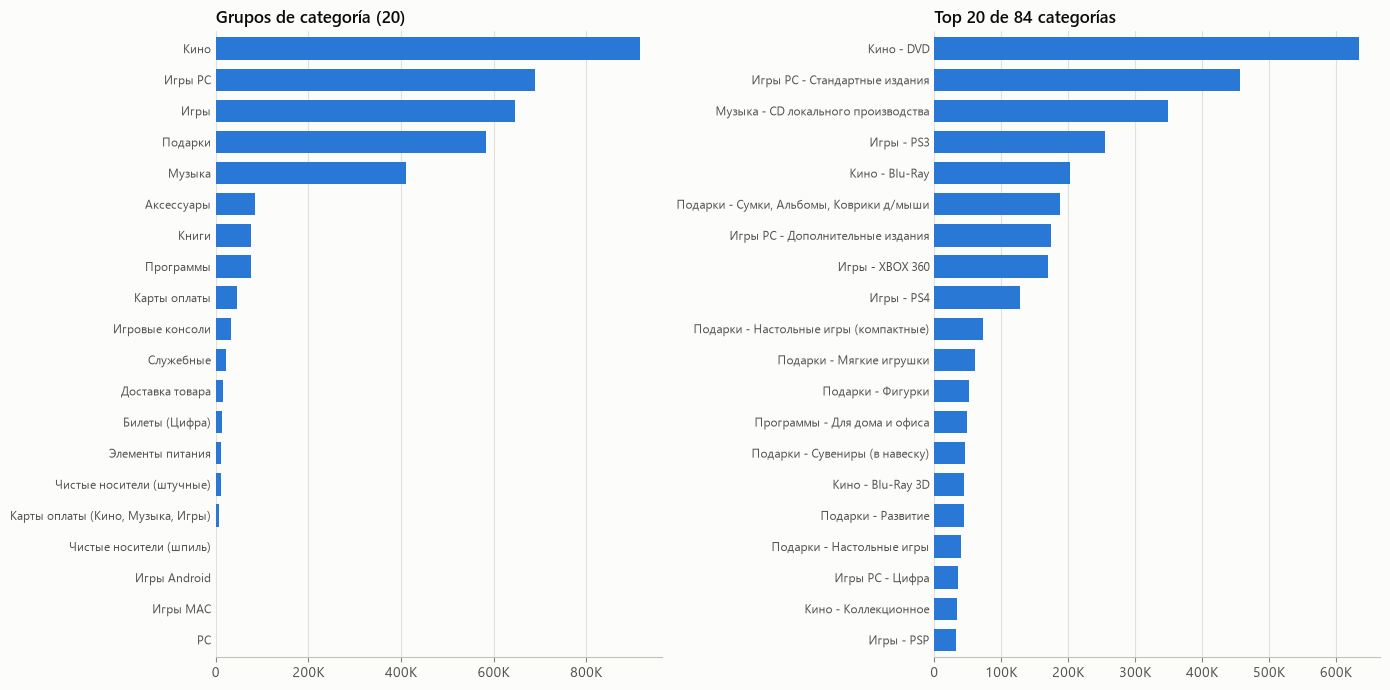

In [79]:
grupos_barras = ventas.groupby("category_group")["item_cnt_day"].sum().sort_values()
categorias_barras = ventas.groupby("item_category_name")["item_cnt_day"].sum().nlargest(20).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
paneles_categoria = [
    (axes[0], grupos_barras, f"Grupos de categoría ({len(grupos_barras)})"),
    (axes[1], categorias_barras, f"Top 20 de {ventas['item_category_name'].nunique()} categorías"),
]
for ax, serie, titulo in paneles_categoria:
    ax.barh([nombre[:42] for nombre in serie.index], serie.to_numpy(), color=AZUL, height=0.72)
    ax.set_title(titulo)
    ax.grid(False)
    ax.xaxis.grid(True)
    ax.margins(y=0.01)
    ax.xaxis.set_major_formatter(formato_miles)
    ax.tick_params(axis="y", labelsize=8.5, length=0)
fig.tight_layout()
guardar(fig, "8c_barras_categorias.png")

**Interpretación:** cinco grupos (`Кино`, `Игры PC`, `Игры`, `Подарки` y `Музыка`) dominan claramente, y a partir del sexto las barras caen a menos de 90 mil unidades. Entre las 84 categorías, `Кино - DVD` y `Игры PC - Стандартные издания` encabezan la lista. La concentración sugiere que las variables de categoría y grupo pueden aportar mucha información al modelo.

### 8.d Mapas de calor por mes

Cada fila se divide entre su propio máximo, de modo que 1 es el mejor mes de esa tienda o categoría. Las celdas grises son meses sin ventas o con ventas netas no positivas.

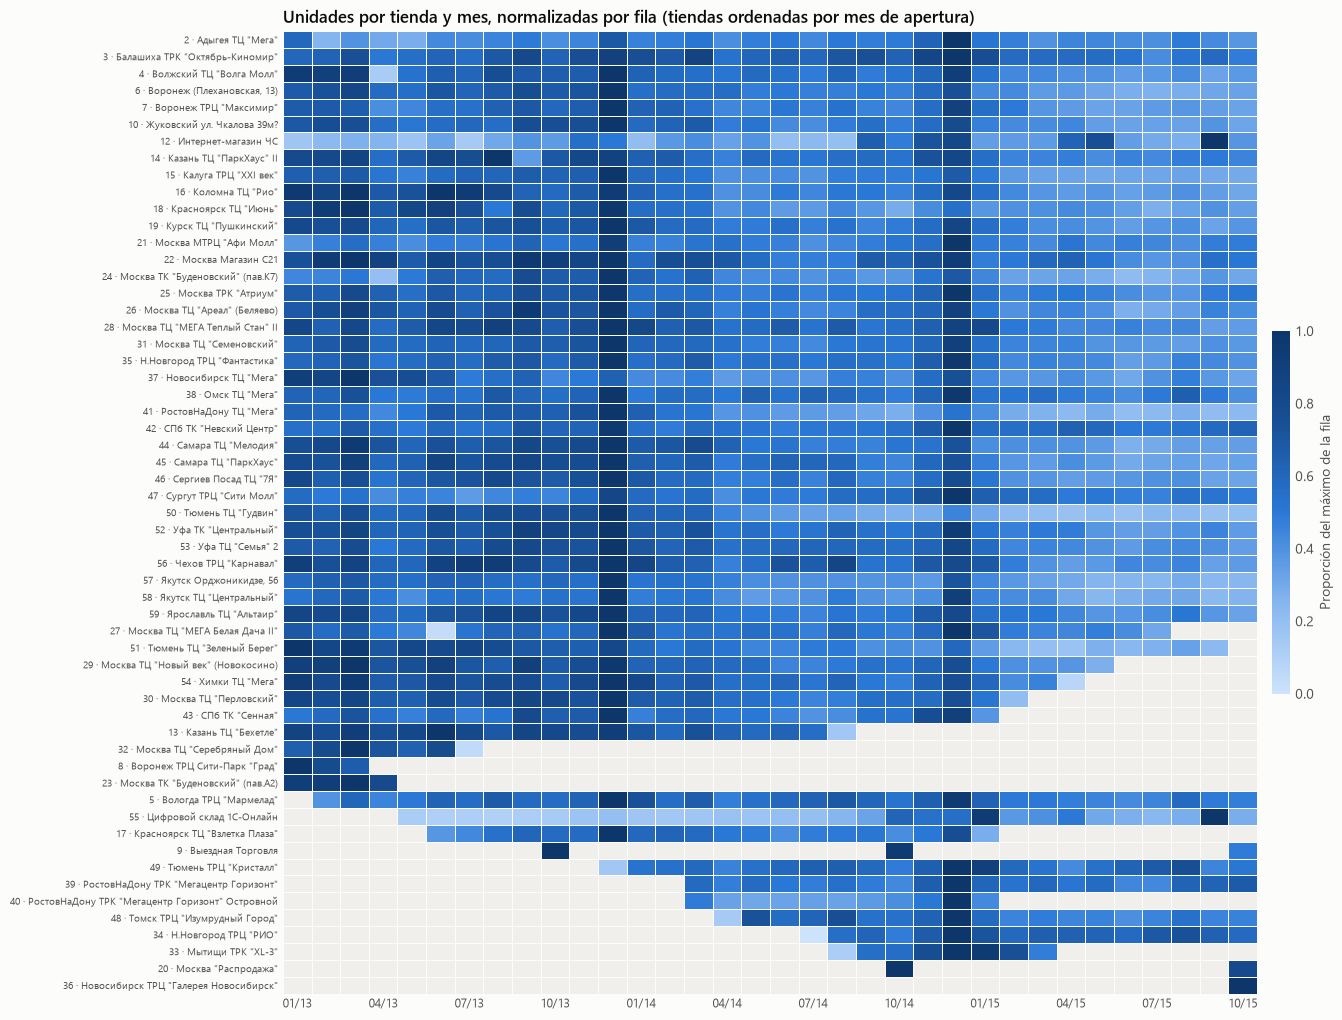

In [80]:
from matplotlib.colors import LinearSegmentedColormap

RAMPA = LinearSegmentedColormap.from_list("azul", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"]).copy()
RAMPA.set_bad("#f0efec")
ETIQUETAS_MES = [f"{(b % 12) + 1:02d}/{13 + b // 12}" for b in range(34)]


def mapa_calor(matriz, etiquetas, titulo, nombre_archivo, alto):
    matriz = matriz.reindex(columns=range(34), fill_value=0).fillna(0)
    normalizada = matriz.div(matriz.max(axis=1), axis=0).where(matriz > 0)
    fig, ax = plt.subplots(figsize=(13, alto))
    malla = ax.pcolormesh(normalizada.to_numpy(), cmap=RAMPA, vmin=0, vmax=1, edgecolors=SUPERFICIE, linewidth=0.6)
    ax.invert_yaxis()
    ax.set_yticks([i + 0.5 for i in range(len(etiquetas))], etiquetas, fontsize=7.5)
    ax.set_xticks([b + 0.5 for b in range(0, 34, 3)], ETIQUETAS_MES[::3], fontsize=8.5)
    ax.tick_params(length=0)
    ax.grid(False)
    ax.spines["bottom"].set_visible(False)
    ax.set_title(titulo)
    barra = fig.colorbar(malla, ax=ax, fraction=0.018, pad=0.015)
    barra.set_label("Proporción del máximo de la fila", color=TINTA_SECUNDARIA)
    barra.outline.set_visible(False)
    guardar(fig, nombre_archivo)


matriz_tienda = ventas.pivot_table(index="shop_id", columns="date_block_num", values="item_cnt_day", aggfunc="sum", fill_value=0)
orden_vida = vida_tiendas.sort_values(["primer_mes", "ultimo_mes"], ascending=[True, False]).index
matriz_tienda = matriz_tienda.reindex(orden_vida)
nombres_tienda = shops.set_index("shop_id")["shop_name"]
etiquetas_mapa = [f"{tienda} · {nombres_tienda[tienda][:50]}" for tienda in matriz_tienda.index]
mapa_calor(matriz_tienda, etiquetas_mapa, "Unidades por tienda y mes, normalizadas por fila (tiendas ordenadas por mes de apertura)", "8d_heatmap_tienda_mes.png", 12.5)

**Interpretación:** la columna oscura de diciembre en 2013 y 2014 aparece en casi todas las tiendas, lo que confirma que la estacionalidad es generalizada. Con el paso de los meses la mayoría se aclara, reflejo de la caída general. Las celdas grises muestran con claridad las aperturas tardías (filas inferiores) y los cierres (a la derecha), así como las tiendas eventuales 9 y 20. Algunas tiendas se comportan distinto: la 12 y la 55, ambas de canal en línea o digital, alcanzan máximos en 2015 fuera de diciembre.

Categorías con al menos 1,000 unidades: 64 de 84


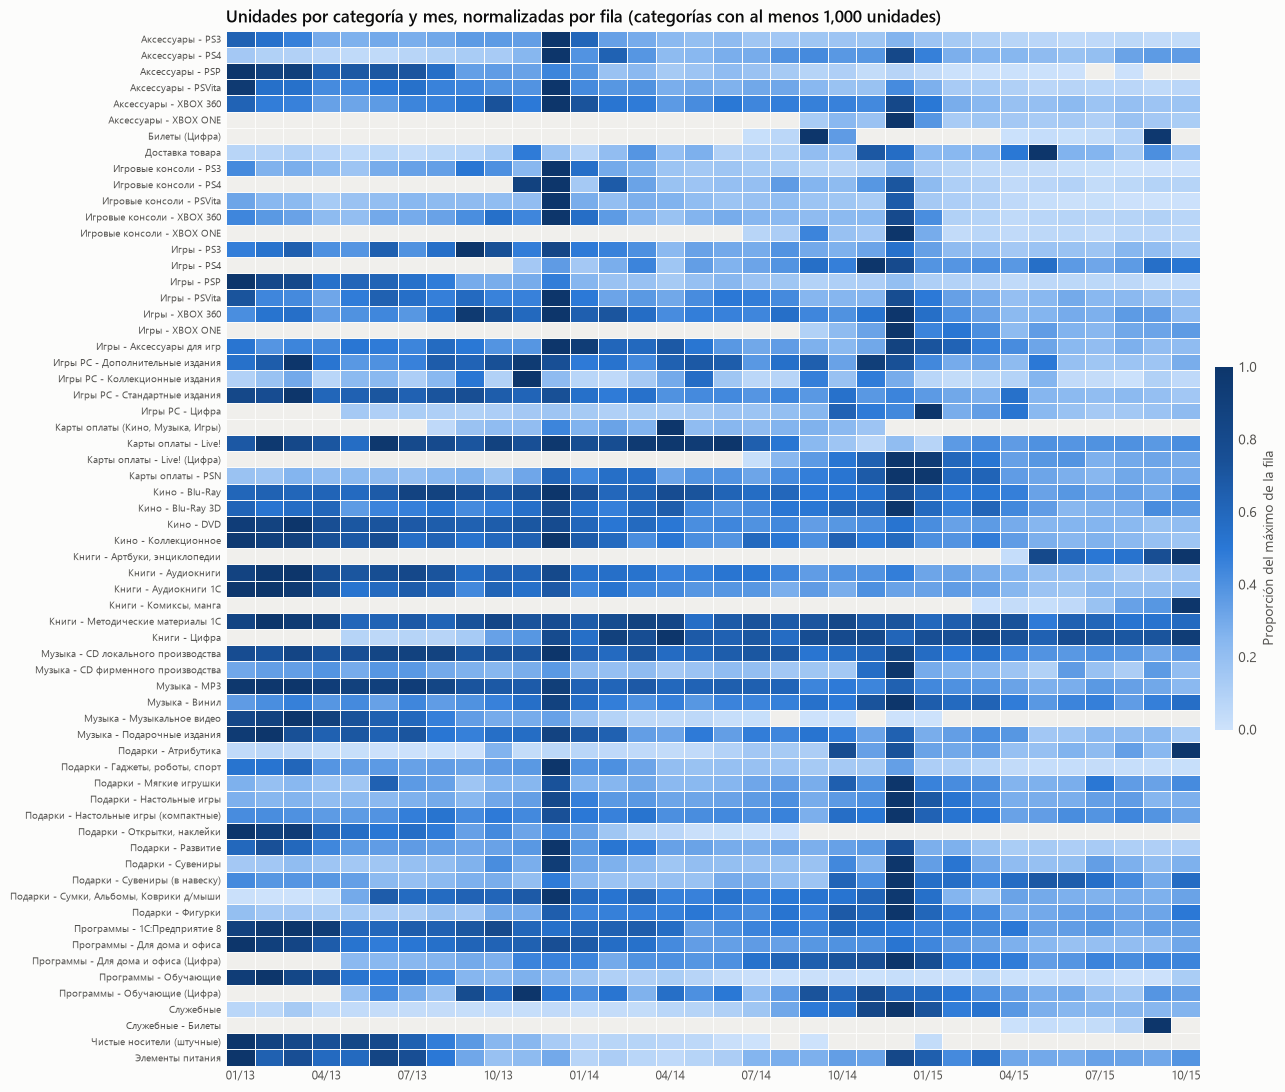

In [81]:
unidades_categoria = ventas.groupby("item_category_name")["item_cnt_day"].sum()
categorias_mapa = sorted(unidades_categoria[unidades_categoria >= 1000].index)
print(f"Categorías con al menos 1,000 unidades: {len(categorias_mapa)} de {len(unidades_categoria)}")

matriz_categoria = (
    ventas[ventas["item_category_name"].isin(categorias_mapa)]
    .pivot_table(index="item_category_name", columns="date_block_num", values="item_cnt_day", aggfunc="sum", fill_value=0)
    .reindex(categorias_mapa)
)
mapa_calor(
    matriz_categoria,
    [nombre[:40] for nombre in categorias_mapa],
    "Unidades por categoría y mes, normalizadas por fila (categorías con al menos 1,000 unidades)",
    "8d_heatmap_categoria_mes.png",
    max(8, len(categorias_mapa) * 0.21),
)

**Interpretación:** el mapa muestra el ciclo de vida de los productos. Las categorías de PS4 y Xbox One aparecen a fines de 2013 y durante 2014, respectivamente, mientras que las de PSP y otros formatos antiguos se apagan con el tiempo. También pierden intensidad `Кино - DVD`, `Музыка - MP3` y `Программы - Обучающие`. Las entradas (`Билеты` y `Служебные - Билеты`) se concentran en torno a septiembre y octubre, y hay categorías nuevas de libros que surgen en 2015. Las categorías no son estables en el tiempo, de modo que el modelo debe tener en cuenta su etapa de vida, no solo su promedio histórico.